Bayesian Machine Learning Project

In [125]:
#pip install ucimlrepo
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge, Lasso
import scipy as sc
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture

from sklearn.linear_model import RidgeCV, LassoCV


In [126]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [127]:
df = pd.read_csv(
    "apartments_for_rent_classified_100K.csv",
    sep=";",
    encoding="utf-8-sig",
    keep_default_na=False,
    na_values=["null", "NaN", "nan", "", "NULL", "N/A", "NA"],
)

/var/folders/1n/rx40y7b55xd26qgp811lth5h0000gn/T/ipykernel_17899/2567181780.py:1: DtypeWarning: Columns (0: id, 1: bedrooms, 2: square_feet, 3: address) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


In [128]:
df.shape # 99826 rows, 22 columns

(99826, 22)

## Data Cleaning

In [129]:
print(df.head())


           id                category                            title  \
0  5668640009  housing/rent/apartment       One BR 507 & 509 Esplanade   
1  5668639818  housing/rent/apartment      Three BR 146 Lochview Drive   
2  5668639686  housing/rent/apartment  Three BR 3101 Morningside Drive   
3  5668639659  housing/rent/apartment            Two BR 209 Aegean Way   
4  5668639374  housing/rent/apartment         One BR 4805 Marquette NE   

                                                                                                                                                           body  \
0             This unit is located at 507 & 509 Esplanade, Redondo Beach, 90277, CAMonthly rental rates range from $2195We have 1 beds units available for rent   
1               This unit is located at 146 Lochview Drive, Newport News, 23602, VAMonthly rental rates range from $1250We have 3 beds units available for rent   
2                This unit is located at 3101 Morningside Drive, R

In [130]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 99826 entries, 0 to 99825
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             99826 non-null  object 
 1   category       99826 non-null  str    
 2   title          99826 non-null  str    
 3   body           99826 non-null  str    
 4   amenities      83749 non-null  str    
 5   bathrooms      99760 non-null  str    
 6   bedrooms       99699 non-null  object 
 7   currency       99822 non-null  str    
 8   fee            99823 non-null  str    
 9   has_photo      99823 non-null  str    
 10  pets_allowed   44267 non-null  str    
 11  price          99821 non-null  float64
 12  price_display  99820 non-null  str    
 13  price_type     99823 non-null  str    
 14  square_feet    99823 non-null  object 
 15  address        7946 non-null   str    
 16  cityname       99521 non-null  str    
 17  state          99521 non-null  str    
 18  latitude       99

### Variables

The following information about the features are from the UCI Machine Learning Repository:
https://archive.ics.uci.edu/dataset/555/apartment+for+rent+classified

category = category of classified <br/>
title = title text of the apartment <br />
body = body text of apartment <br />
amenities = like AC, basketball,cable, gym, internet access, pool, refrigerator etc. <br />
bathrooms = number of bathrooms <br />
bedrooms = number of bedrooms <br />
currency = price in current <br />
fee = fee <br />
has_photo = photo of apartment <br />
pets_allowed = what pets are allowed dogs/cats etc. <br />
price = rental price of apartment <br />
price_display = price converted into display for reader <br />
price_type = price in USD <br />
square_feet = size of the apartment <br />
address =  where the apartment is located <br />
cityname =  where the apartment is located <br />
state =  where the apartment is located <br />
latitude = where the apartment is located <br />
longitude = where the apartment is located <br />
source = origin of classified <br />
time = when classified was created <br />

In [131]:
# Number of unique values for each variable
df.nunique()

id               99742
category            10
title            58660
body             94806
amenities         9843
bathrooms           18
bedrooms            19
currency             3
fee                  5
has_photo            6
pets_allowed         7
price             3691
price_display     3723
price_type           6
square_feet       4188
address           7774
cityname          2984
state               53
latitude          7215
longitude         7272
source              25
time             75541
dtype: int64

#### 'id'

There are 99742 unique ID-s and 99826 instances in total, so we inspect whether the duplicate ID-s indicate the same listing reposted at different times or websites.

In [132]:
dup_ids = df['id'][df['id'].duplicated(keep=False)].unique()
dup_df = df[df['id'].isin(dup_ids)].copy()

In [133]:
results = []

for listing_id, group in dup_df.groupby('id'):
    
    row = {
        'id': listing_id,
        'n_rows': len(group)
    }
    
    differing_cols = []
    
    for col in df.columns:
        if col == 'id':
            continue
        
        # check whether all values are same
        same = group[col].nunique(dropna=False) == 1
        
        row[f'{col}_same'] = same
        
        if not same:
            differing_cols.append(col)
    
    row['identical_rows'] = len(differing_cols) == 0
    row['n_differing_cols'] = len(differing_cols)
    row['differing_columns'] = differing_cols
    
    results.append(row)

dup_summary = pd.DataFrame(results)

In [134]:
dup_summary[~dup_summary['identical_rows']]

,id,n_rows,category_same,title_same,body_same,amenities_same,bathrooms_same,bedrooms_same,currency_same,fee_same,has_photo_same,pets_allowed_same,price_same,price_display_same,price_type_same,square_feet_same,address_same,cityname_same,state_same,latitude_same,longitude_same,source_same,time_same,identical_rows,n_differing_cols,differing_columns


The duplicates are exactly the same, so we only keep one intance of each, as duplicates would not add new information to price prediction or clustering.

In [135]:
df = df.drop_duplicates().reset_index(drop=True)

#### 'time'


In [136]:
# Convert time column to datetime
df['time'] = pd.to_numeric(df['time'], errors='coerce')
df['time'] = pd.to_datetime(df['time'], unit='s')

In [137]:
# Sort by time in ascending order
df = df.sort_values(by='time', ascending=True).reset_index(drop=True)

print("Data sorted by time (ascending):")
print(df['time'].head(10))
print("\n...")
print(df['time'].tail(10))

Data sorted by time (ascending):
0   2018-12-07 09:20:18
1   2018-12-07 09:20:32
2   2018-12-07 09:20:44
3   2018-12-07 09:20:55
4   2018-12-07 09:20:58
5   2018-12-07 09:21:14
6   2018-12-07 09:21:15
7   2018-12-07 09:21:17
8   2018-12-07 09:21:18
9   2018-12-07 09:21:41
Name: time, dtype: datetime64[s]

...
99732   2019-12-26 11:42:48
99733   2019-12-26 12:09:31
99734   2019-12-26 12:09:46
99735   2019-12-26 20:17:05
99736                   NaT
99737                   NaT
99738                   NaT
99739                   NaT
99740                   NaT
99741                   NaT
Name: time, dtype: datetime64[s]


The output above shows that the entries were created between 7th December 2018 and 26th December 2019, except for 6 instances, where the data is NaT (Not a Time). 
Time of creation of posted listing could carry information, therefore, we group listings by year and month, and drop the instances with NaT-s.

In [138]:
df = df.dropna(subset=['time'])

In [139]:
df["year_month"] = df["time"].dt.to_period("M")
# Sort by time in ascending order
df = df.sort_values(by='year_month', ascending=True).reset_index(drop=True)

print("Data sorted by time (ascending):")
print(df['year_month'].head(10))
print("\n...")
print(df['year_month'].tail(10))

Data sorted by time (ascending):
0    2018-12
1    2018-12
2    2018-12
3    2018-12
4    2018-12
5    2018-12
6    2018-12
7    2018-12
8    2018-12
9    2018-12
Name: year_month, dtype: period[M]

...
99726    2019-12
99727    2019-12
99728    2019-12
99729    2019-12
99730    2019-12
99731    2019-12
99732    2019-12
99733    2019-12
99734    2019-12
99735    2019-12
Name: year_month, dtype: period[M]


In [140]:
df["year_month"] = df["time"].dt.to_period("M").astype(str)
df["year_month"] = df["year_month"].astype("category")

In [141]:
# Drop the 'time' column
df = df.drop(columns=['time'])

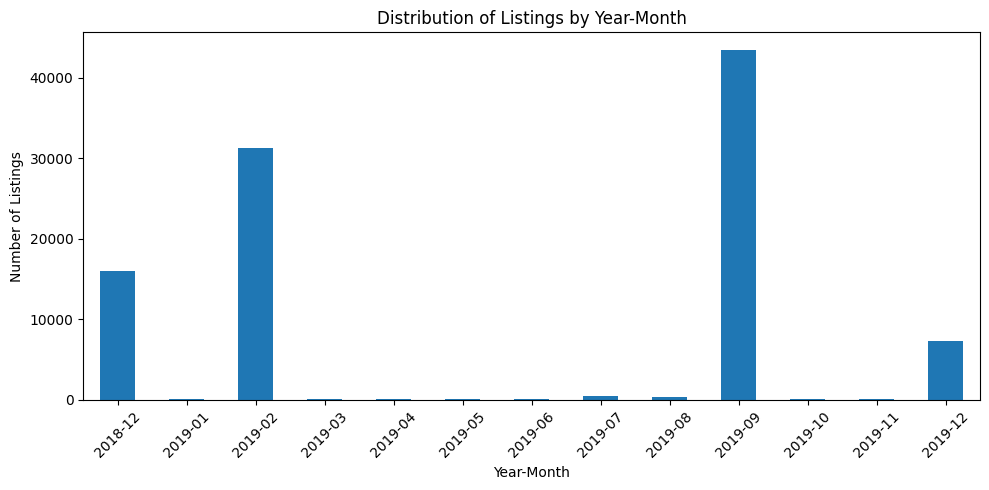

In [142]:
# Count observations per month
month_counts = df["year_month"].value_counts().sort_index()

# Plot
plt.figure(figsize=(10,5))
month_counts.plot(kind="bar")

plt.title("Distribution of Listings by Year-Month")
plt.xlabel("Year-Month")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The plot above shows the concentration of recorded timestamps of the classified advirtisement creation is in only a few months, suggesting that the timestamp is reflecting data collection or scraping patterns rather than the market dynamics. Therefore, the variable 'year_month', which was created based on 'time', was also excluded from the modelling process.

In [143]:
# Drop the 'year_month' column
df = df.drop(columns=['year_month'])

#### Numerical variables

In [144]:
num_cols = [
    "bathrooms",
    "bedrooms",
    "price",
    "square_feet",
    "latitude",
    "longitude"
]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce') # Convert to numeric, coercing errors to NaN

### Missing values

In [145]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct)

address          92.036978
pets_allowed     55.653926
amenities        16.106521
bathrooms         5.593768
state             0.302799
cityname          0.302799
bedrooms          0.124328
longitude         0.025066
latitude          0.025066
price             0.001003
price_display     0.001003
price_type        0.000000
square_feet       0.000000
id                0.000000
category          0.000000
has_photo         0.000000
fee               0.000000
currency          0.000000
body              0.000000
title             0.000000
source            0.000000
dtype: float64


In [146]:
# The unique values in each variable
for col in df.columns:
    print(f"\n--- {col} ---")
    print(f"Unique values: {df[col].nunique()}")
    print(df[col].value_counts(dropna=False))


--- id ---
Unique values: 99736
id
5121046168    1
5122226556    1
5122226604    1
5122226626    1
5122226663    1
             ..
5668610609    1
5668610615    1
5668610597    1
5668610602    1
5669438542    1
Name: count, Length: 99736, dtype: int64

--- category ---
Unique values: 7
category
housing/rent/apartment            99675
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/short_term               4
housing/rent/home                     4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64

--- title ---
Unique values: 58656
title
Apartment in great location                           1066
Apartment in prime location                           1031
Apartment in quiet area, spacious with big kitchen    1024
Super Cute! Apartment for Rent!                       1020
This Apartment is a must see!                         1005
                                                      ... 
T

We investigate variables with high proportion of missing values, namely: 'pets_allowed', 'amenities', 'bathrooms'. The variable 'address' is skipped and will be dropped because the project's focus is city. The other columns (variables) contain less than 1% of missing values, and considering that the sample size is large, the corresponding rows (instances) are removed.

#### 'pets_allowed'

In [147]:
print(f"Unique values: {df['pets_allowed'].nunique()}")
print(df['pets_allowed'].value_counts(dropna=False))


Unique values: 5
pets_allowed
NaN               55507
Cats,Dogs         37182
None               5074
Cats               1845
Dogs                127
Cats,Dogs,None        1
Name: count, dtype: int64


There entry with 'Cats,Dogs,None' suggests a mistake, so we check the body 'text'.

In [148]:
df[df["pets_allowed"] == "Cats,Dogs,None"] # the text body shows that this property allows cats

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source
16104,5168200637,housing/rent/apartment,1 BR In St Paul Southwest,xxxxxxxxxx.xxx Listing ID xxx-xxx-xxxx. AVAILABLE NOW OR March first Large one Beds (720 sq-ft) Apartments in Peaceful Residential Neighborhood Small eleven Unit Building On Site Laundry (NO CHARGE!) We Love Cats! NO PET FEE or PET DEPOSIT! Near Busline Carpeting/H... List ID: 551889395 | RealRentals.com,NaN,1.0,1.0,USD,No,Thumbnail,"Cats,Dogs,None",930.0,$930,Monthly,720.0,NaN,Saint Paul,MN,44.8935,-93.1084,RealRentals


In [149]:
df[df["pets_allowed"] == "None"].head(3)

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source
66,5122232093,housing/rent/apartment,Beautiful Updated Two BR Unit In Hills/Mills College Area,"CA. 2 Bedrooms, one Bathrooms, Largest Of All The Units, Open Kitchen with Bar, Rain Style Shower, Water & Garbage Paid For, Off-parking on street, Storage Spaces, Newly remodeled, Immediate Access to 580 Freeway, Laundry On-site, NO PETS, This beautiful 2 beds unit just became available and is looking for a new tenant! The unit was newly remodeled inside & out! The building has new windows, roof, exterior siding & paint. The unit features bamboo floors, tiled bathrooms and kitchen, as well as granite countertops and custom cabinetry. There is on-site laundry as well as parking and storage for your convenience.","Parking,Storage",1.0,2.0,USD,No,Yes,None,2195.0,"$2,195",Monthly,1000.0,NaN,Oakland,CA,37.7627,-122.1571,RentDigs.com
113,5122230759,housing/rent/apartment,Apartment for rent in Sunrise. Parking Available!,"Great Bright Corner Unit in very excellent condition. New AC and hotwater heater. one parking Electric heating, Hot water heat, Central heat, Central a/v Storage room, Living/dedicated dining area room combination Refrigerator, Electric range and oven Vinyl, Tile Waterfront property, Lake frontage Lake Guest parking, Dedicated parking Swimming Pool Community secure features, Shared pool, Community exercise area, Club house, Community laundry facilities Concrete block stucco Cable TELEVISION Public water supply, Public sewer service Housing For Older Persons, No ok for pets. Close to dining and shops, bright, gas stove, trash included.","AC,Cable or Satellite,Clubhouse,Parking,Pool,Refrigerator,Storage,TV",2.0,2.0,USD,No,Yes,None,1250.0,"$1,250",Monthly,850.0,NaN,Fort Lauderdale,FL,26.1492,-80.2742,RentDigs.com
133,5122220987,housing/rent/apartment,"Gorgeous San Antonio, Three BR, 2.50 BA","Come see this beautiful 3 bedrooms 2. five bathrooms home in the desirable Spring s Subdivision: Move in READY. No ok for pets. Appliances: Kitchen microwave, Stove, Garbage Disposal. Amenities: Shared swimming pool, Park Play Area, Basketball, Club house.","Basketball,Clubhouse,Garbage Disposal,Playground,Pool",NaN,3.0,USD,No,Yes,None,1500.0,"$1,500",Monthly,1507.0,NaN,San Antonio,TX,29.4622,-98.6704,RentDigs.com


In [150]:
# pd.crosstab(
#     df["source"],
#     df["pets_allowed"].isna(),
#     normalize="index"
# )

In [151]:
# tab = pd.crosstab(
#     df["source"],
#     df["pets_allowed"].isna(),
#     normalize="index"
# )

# tab.plot(
#     kind="bar",
#     stacked=True,
#     figsize=(12,6)
# )
# plt.ylabel("Proportion")
# plt.title("Missing pet-policy values by source")
# plt.legend(["Present", "Missing"])
# plt.xticks(rotation=45, ha="right")
# plt.show()
# # The outputs show that some sources do not provicde information about pet policy at all, while others do, suggesting that missingness is not at random (MNAR). 

 The body texts confirm that "None" means that no pets are allowed, rather than missing information. Hence, missing 'pets_allowed' entries are treated as unknown policies. The original pet-policy categories are regrouped into broader classes because several labels are rare or inconsistently recorded. The new variable 'pets_policy' differentiates between pet-friendly, no-pet listings, and unknown pet policies. In the modelling process, the 'pets_policy' is considered, hence, the variable 'pets_allowed' is dropped.

In [152]:
def regroup_pets(x):
    if pd.isna(x):
        return "unknown"
    
    x = str(x).strip()
    
    if x == "None":
        return "no_pets"
    
    # any other non-missing listed pet policy counts as pet-friendly
    return "pets_allowed"

df["pets_policy"] = df["pets_allowed"].apply(regroup_pets).astype("category")
#df["pets_policy"].value_counts()

Then, the variable 'pets_policy' is encoded using dummy variables with “Yes” as the reference category.

In [153]:
df["pets_policy"] = pd.Categorical(
    df["pets_policy"],
    categories=["pets_allowed", "no_pets", "unknown"]
)

df = pd.get_dummies(df, columns=["pets_policy"], drop_first=True)

In [154]:
# drop 'pets_allowed'
df = df.drop(columns=['pets_allowed'])

#### 'amenities'

In [155]:
df.loc[
    df["amenities"].isna()
].sample(3, random_state=451)

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,pets_policy_no_pets,pets_policy_unknown
91118,5508835766,housing/rent/apartment,"Reno, Great Location, Studio Apartment.","Live in a prime location when you make City Center Apartments your home. Our studio and one beds apartments for rent in Reno, Nevada, are central to it all. We are within walkable distance of great food and entertainment, including Greater Nevada Field, The Discovery Museum, and Pioneer Center for the Performing Arts. When you rent an Center Apartments, you ll enjoy having your utilities covered in your monthly rent and excellent community amenities to enjoy year-round. Pets - allowed Cats - one allowed, Rent $25. 00, Deposit $200 Dogs - one allowed, Max weight 25 pound each, Rent $25. 00, Deposit $200. 00.",NaN,1.0,1.0,USD,No,Yes,772.0,$772,Monthly,306.0,NaN,Reno,NV,39.5264,-119.8122,RentDigs.com,False,True
99200,5664598178,housing/rent/apartment,One BR 690 Anderson Ave.,"This unit is located at 690 Anderson Ave., Cliffside Park, 07010, NJMonthly rental rates range from $2350 - $2850We have one - two beds units available for rent",NaN,1.0,1.0,USD,No,Thumbnail,2350.0,"$2,350",Monthly,872.0,690 Anderson Avenue,Cliffside Park,NJ,40.8211,-73.9890,RentLingo,False,False
22680,5198393879,housing/rent/apartment,This rental is a Laplace apartment Bluebonnet.,"The property features a unit type of 2 beds/one baths with rent starting at $750, the market average is $1, 393.",NaN,1.0,2.0,USD,No,Thumbnail,750.0,$750,Monthly,1150.0,NaN,La Place,LA,30.0550,-90.4805,RentDigs.com,False,True


In [156]:
all_amenities = (
    df["amenities"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

In [157]:
amenity_counts = all_amenities.value_counts()

print(amenity_counts)

amenities
Parking               43922
Pool                  43624
Gym                   37396
Patio/Deck            26571
Washer Dryer          26055
Storage               21662
Clubhouse             19138
Dishwasher            16635
AC                    15825
Fireplace             14948
Refrigerator          14943
Cable or Satellite    12552
Playground            11353
Internet Access       11093
Wood Floors            8899
Gated                  8669
Tennis                 8511
TV                     4499
Elevator               4339
Basketball             4151
Hot Tub                4004
Garbage Disposal       3882
View                   2093
Alarm                   364
Doorman                 221
Luxury                  211
Golf                     27
Name: count, dtype: int64


In [158]:
# work with amenities that appear in at least 10% of listings

# Define threshold (10%)
threshold = 0.10 * len(df)

# Select amenities appearing in at least 10% of listings
amenities_keep = amenity_counts[amenity_counts >= threshold].index.tolist()

print(amenities_keep)

['Parking', 'Pool', 'Gym', 'Patio/Deck', 'Washer Dryer', 'Storage', 'Clubhouse', 'Dishwasher', 'AC', 'Fireplace', 'Refrigerator', 'Cable or Satellite', 'Playground', 'Internet Access']


In [159]:
for a in amenities_keep:
    col = a.lower().replace(" ", "_").replace("/", "_")
    df[col] = df["amenities"].str.contains(a, na=False).astype(int)

In [160]:
df["amenities_missing"] = df["amenities"].isna().astype(int)

In [161]:
all_amenities

0        Cable or Satellite
0                  Elevator
0                       Gym
0           Internet Access
0                   Parking
                ...        
99733          Refrigerator
99734            Dishwasher
99734      Garbage Disposal
99734          Refrigerator
99735       Internet Access
Name: amenities, Length: 365587, dtype: str

In [162]:
df = df.drop(columns="amenities")

#### 'bathrooms'

We investigate whether the reason of missingness in the variable 'bathrooms'.

In [163]:
df.loc[
    df["bathrooms"].isna()
].sample(3, random_state=451)

,id,category,title,body,bathrooms,bedrooms,currency,fee,has_photo,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,pets_policy_no_pets,pets_policy_unknown,parking,pool,gym,patio_deck,washer_dryer,storage,clubhouse,dishwasher,ac,fireplace,refrigerator,cable_or_satellite,playground,internet_access,amenities_missing
7595,5122453252,housing/rent/apartment,Super Cute! Apartment for Rent. Parking Available!,"Complete furnished, updated, beautiful and spacious 1 beds/one full size bathrooms,/1half bathroom in a resort-style building Casa Costa. With stainless appliances and granite countertop in the kitchen. Open balcony, washer and dryer in the unit. Close to the beach and Interstate 95. Mangrove Park is just behind the building, great for outdoor lovers & pet friendly spot. Available amenities two pools, gymnasium, sauna, spa, professional center, concierge service, valet service Very nice to be! Water, cable and internet included.",NaN,1.0,USD,No,Yes,1925.0,"$1,925",Monthly,835.0,NaN,Boynton Beach,FL,26.5256,-80.0672,RentDigs.com,False,True,1,0,1,1,1,0,0,0,0,0,0,1,0,1,0
86919,5508821304,housing/rent/apartment,Dallas Value!,"Square footage: 1439 sq-ft, unit number: 1404T. Enjoy urban luxurious living with easy access to Dallas most exciting West. Discover a fresh new look and exciting upgrades in an incredibly convenient location. We re nestled between the High 5 and Uptown, out of the hustle and bustle but moments away from everything. Explore trendy restaurants in Knox-Henderson and boho bars on Greenville. Shop Mall, Preston Hollow, and the West Village. Find the perfect retreat with our wide selection of floorplans, which include spacious townhomes and studio suites. Live in a true community with a neighborhood feel, where you can stroll under tree-lined streets and meet pet park. Embrace the vibrant city spirit and create the lifestyle you ve imagined. Come home to 75 West.",NaN,2.0,USD,No,No,1810.0,"$1,810",Monthly,1439.0,NaN,Dallas,TX,32.9012,-96.7916,RentDigs.com,False,True,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
43436,5198209130,housing/rent/apartment,Welcome Home Welcome home to Colonial Arms Apartments!,"Imagine yourself relaxing on the sundeck by the beautiful swimming pool, saying hello to your neighbor while watching the sunset from your patio, or meeting new play-area. Life really is a Arms! Each apartment home has sliding glass doors that that open onto your private balcony or patio, wall-to-wall carpeting keeps a peaceful environment and large closets enhance the comfort and convenience of your home. The perks don't door step! Centered near The, Sentara Virginia Beach General Hospital and local schools, Colonial Arms is in a location that can't be beat. A short down Laskin takes you to the Virginia Beach Boardwalk and easy access to I- s. Come see why residents love Arms Apartments, where exceptional living meets exceptional value. today for an appointment! TTY 711. $300 No-refund PetDeposit. No Aggressive Breeds. $25 per petmonthly petrent. Pet Restrictions Apply. two Pet Limit Per Household. Cats & Smaller dogs allowed. Max weight is 50 lbs. Per Pet.",NaN,3.0,USD,No,Thumbnail,1345.0,"$1,345",Monthly,1115.0,NaN,Virginia Beach,VA,36.8344,-76.0258,RentDigs.com,False,False,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0


From some of the variable 'body' it can be seen that some missing bathroom values could be identified from the listing descriptions. However, the text is often unclear or inconsistently written, so it would be costly to manually extract information for all rows. 
Thus, unknown bathroom values were handled as a separate category. 

In [164]:
df.groupby(df["bathrooms"].isna())["price"].median()

bathrooms
False    1350.0
True     1450.0
Name: price, dtype: float64

Comparing the median price of the properties with and without missing values shows that there is a differece between the median prices, suggesting that the missingness is not random. Thus, we create a column with binary variable inidicating whether the number of bathroom information exist. We also keep the 'bathrooms' variable and impute the missing values with the median of bathroom numbers at proporties with the same number of bedrooms.

In [165]:
# 1. indicator
df["bathrooms_missing"] = df["bathrooms"].isna().astype(int) 

# 2. group-based
df["bathrooms"] = df["bathrooms"].fillna(
    df.groupby("bedrooms")["bathrooms"].transform("median") 
)

# 3. fallback
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median()) # if there are still missing values after group-based imputation, fill with overall median

In [166]:
# check the remaining percentage of missing values

missing_pct = df.isna().mean() * 100
print(missing_pct.sort_values(ascending=False))

address                92.036978
state                   0.302799
cityname                0.302799
bedrooms                0.124328
longitude               0.025066
latitude                0.025066
price                   0.001003
price_display           0.001003
id                      0.000000
washer_dryer            0.000000
storage                 0.000000
clubhouse               0.000000
ac                      0.000000
dishwasher              0.000000
gym                     0.000000
fireplace               0.000000
refrigerator            0.000000
cable_or_satellite      0.000000
playground              0.000000
internet_access         0.000000
amenities_missing       0.000000
patio_deck              0.000000
source                  0.000000
pool                    0.000000
parking                 0.000000
pets_policy_unknown     0.000000
pets_policy_no_pets     0.000000
category                0.000000
square_feet             0.000000
price_type              0.000000
has_photo 

#### Dropping the rest of the instances with missing values

We can now see that the variables contain less than 1% of missing values (except for 'address' but it will be dropped later), so we remove all rows with missing values, without considering the variable 'address'.

In [167]:
# original dataset size
n_before = len(df)

# columns to consider (exclude 'address')
cols_except_address = df.columns.drop("address")

# drop rows with missing values in all other columns
df = df.dropna(subset=cols_except_address)

# check how many were removed
n_after = len(df)
print(f"Dropped {n_before - n_after} rows, ({(n_before - n_after)/n_before:.2%}) of the dataset")

Dropped 427 rows, (0.43%) of the dataset


### Other Variables

In [168]:
# The unique values in each variable
for col in df.columns:
    print(f"\n--- {col} ---")
    print(f"Unique values: {df[col].nunique()}")
    print(df[col].value_counts(dropna=False))

# check: category, has_photo , price_type, cityname, source


--- id ---
Unique values: 99309
id
5121046168    1
5122226556    1
5122226604    1
5122226626    1
5122226663    1
             ..
5668610609    1
5668610615    1
5668610597    1
5668610602    1
5669438542    1
Name: count, Length: 99309, dtype: int64

--- category ---
Unique values: 7
category
housing/rent/apartment            99248
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/short_term               4
housing/rent/home                     4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64

--- title ---
Unique values: 58378
title
Apartment in great location                           1063
Apartment in prime location                           1026
Apartment in quiet area, spacious with big kitchen    1021
Super Cute! Apartment for Rent!                       1014
This Apartment is a must see!                         1000
                                                      ... 
T

#### 'category'

In [169]:
df["category"].value_counts(normalize=True)

category
housing/rent/apartment            0.999386
housing/rent/commercial/retail    0.000423
housing/rent                      0.000070
housing/rent/short_term           0.000040
housing/rent/home                 0.000040
housing/rent/condo                0.000030
housing/rent/other                0.000010
Name: proportion, dtype: float64

Observations belonging to categories that are not specified as apartments are removed, as they might represent different types of listings and are only present in a negligible proportion of the dataset. Then, the variable 'category' is removed.

In [170]:
df = df[df["category"] == "housing/rent/apartment"]
df = df.drop(columns=["category"])

#### 'has_photo'

In [171]:
df["has_photo"].value_counts(normalize=True)

has_photo
Yes          0.562873
Thumbnail    0.344299
No           0.092828
Name: proportion, dtype: float64

In [172]:
df.groupby("has_photo")["price"].median()

has_photo
No           1433.0
Thumbnail    1300.0
Yes          1370.0
Name: price, dtype: float64

We can see that the median price of each category is different, with listings with no photo having higher price. This differs from common intuition, so it suggests that the variable 'has_photo' could capture important information. Thus, we convert the original 'has_photo' into 2 binary variables: 'has_photo_Thumbnail' and 'has_photo_No', using listings with full photos (Yes) as the reference category.

In [173]:
df["has_photo"] = pd.Categorical(
    df["has_photo"],
    categories=["Yes", "Thumbnail", "No"]
)

df = pd.get_dummies(df, columns=["has_photo"], drop_first=True)

#### 'price_type'

In [174]:
df["price_type"].value_counts(normalize=True)

price_type
Monthly    0.99997
Weekly     0.00003
Name: proportion, dtype: float64

As the majority of prices are listed as monthly, we convert the weekly price types into monthly and drop the variable 'price_type'.

In [175]:
df.loc[df["price_type"] == "Weekly", "price"] *= (52 / 12) # 52 weeks / 12 months
df = df.drop(columns=['price_type'])

#### 'cityname'

In [176]:
city_counts = df["cityname"].value_counts()

In [177]:
city_counts

cityname
Dallas         2857
Denver         2753
Los Angeles    2399
Las Vegas      1847
Arlington      1577
               ... 
Wenatchee         1
Kankakee          1
Horicon           1
Channelview       1
Locust            1
Name: count, Length: 2978, dtype: int64

There are 2979 unique cities, and some of them only contain small number of instances. Considering that we work with city-level medians, we keep with sufficient amount of instances. 

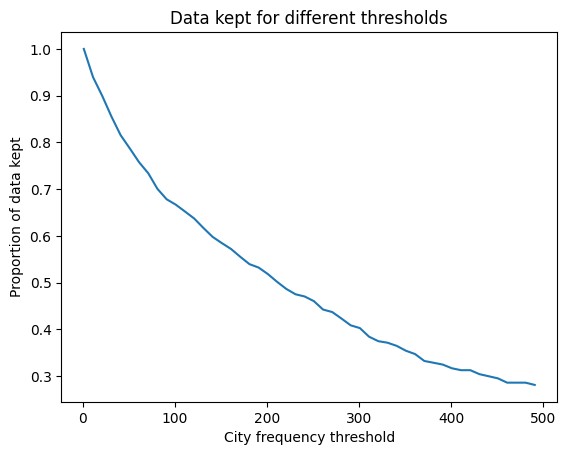

In [178]:
thresholds = range(1, 500, 10)
percentages = []

for t in thresholds:
    valid = city_counts[city_counts >= t].index
    rows_kept = df["cityname"].isin(valid).sum()
    percentages.append(rows_kept / len(df))

plt.plot(thresholds, percentages)
plt.xlabel("City frequency threshold")
plt.ylabel("Proportion of data kept")
plt.title("Data kept for different thresholds")
plt.show()

In [179]:
thresholds = [50, 100, 150, 200, 250, 500]

for t in thresholds:
    valid = city_counts[city_counts >= t].index
    rows_kept = df["cityname"].isin(valid).sum()
    
    print(f"Threshold {t}: kept {rows_kept} rows ({rows_kept/len(df):.2%})")

Threshold 50: kept 78459 rows (79.05%)
Threshold 100: kept 66268 rows (66.77%)
Threshold 150: kept 58313 rows (58.75%)
Threshold 200: kept 52043 rows (52.44%)
Threshold 250: kept 45944 rows (46.29%)
Threshold 500: kept 27406 rows (27.61%)


A minimum threshold of 100 listings per city was chosen to ensure that city-level median prices are based on a sufficiently large sample. The threshold also retains a substantial proportion of the data.

In [180]:
threshold = 100
valid_cities = city_counts[city_counts >= threshold].index

df = df[df["cityname"].isin(valid_cities)]

In [181]:
city_means = df.groupby("cityname")["price"].median()

print(city_means.describe())

count     212.000000
mean     1421.287736
std       543.461045
min       550.000000
25%      1096.750000
50%      1298.000000
75%      1557.000000
max      3940.000000
Name: price, dtype: float64


The median rental price varies substantially across cities, ranging from approximately $550 to nearly $3940, with a standard deviation of $543.46. This indicates that location is a major determinant of rental prices.

### Removing variables 

The 'title', 'body', 'price_display' variables are dropped because the information they contain can be found in other variables. We focus on which city the property is located, thus, the other location related variables, specifically 'address', 'state', 'latitude', and 'longitude' are also dropped. The 'id', 'source', and 'currency' (as it is the same for all listings) variables do not contain information for the price prediction and clustering tasks, so they are also not considered.

In [182]:
df = df.drop(columns=['id', 'title', 'body', 'currency', 'price_display', 'address', 'state', 'latitude', 'longitude', 'source'])

### Data types

In [183]:
df.dtypes

bathrooms              float64
bedrooms               float64
fee                        str
price                  float64
square_feet            float64
cityname                   str
pets_policy_no_pets       bool
pets_policy_unknown       bool
parking                  int64
pool                     int64
gym                      int64
patio_deck               int64
washer_dryer             int64
storage                  int64
clubhouse                int64
dishwasher               int64
ac                       int64
fireplace                int64
refrigerator             int64
cable_or_satellite       int64
playground               int64
internet_access          int64
amenities_missing        int64
bathrooms_missing        int64
has_photo_Thumbnail       bool
has_photo_No              bool
dtype: object

In [184]:
# convert 'fee' to binary
df["fee"] = df["fee"].map({"Yes": 1, "No": 0})

In [185]:
# convert boolean columns to integers (binary)
df = df.astype({col: "int" for col in df.select_dtypes("bool").columns})

## Exploratory Data Analysis and Feature Engineering

### Skewness and Outliers

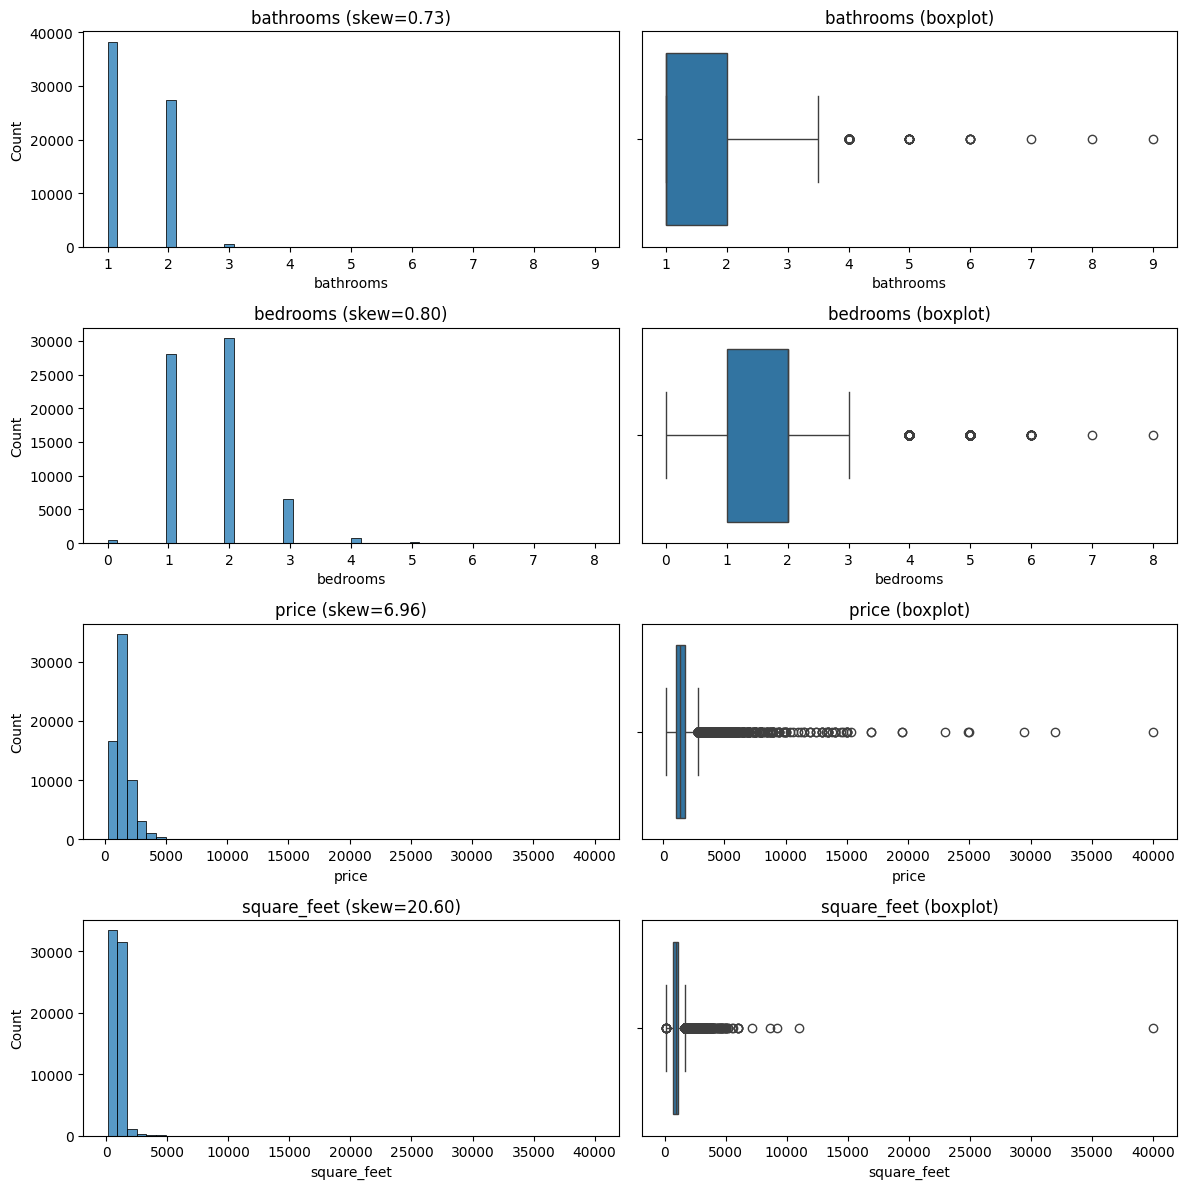

In [186]:
num_cols = ["bathrooms", "bedrooms", "price", "square_feet"]

# Compute skewness
skew_vals = df[num_cols].skew()

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 12))

for i, col in enumerate(num_cols):
    # Histogram
    sns.histplot(df[col], bins=50, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (skew={skew_vals[col]:.2f})")
    
    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} (boxplot)")

plt.tight_layout()
plt.show()

#### 'bedrooms'

In [187]:
df['bedrooms'].value_counts()

bedrooms
2.0    30439
1.0    27994
3.0     6500
4.0      699
0.0      472
5.0      142
6.0       20
7.0        1
8.0        1
Name: count, dtype: int64

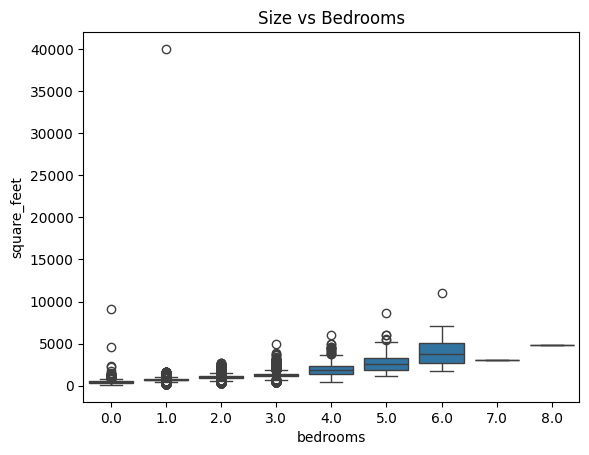

In [188]:
sns.boxplot(x="bedrooms", y="square_feet", data=df)
plt.title("Size vs Bedrooms")
plt.show()

In [189]:
df.groupby("bedrooms")["square_feet"].describe()

,count,mean,std,min,25%,50%,75%,max
bedrooms,,,,,,,,
0.0,472.0,528.243644,510.574060,101.0,365.0,450.0,550.0,9175.0
1.0,27994.0,728.669679,274.805772,156.0,650.0,726.0,802.0,40000.0
2.0,30439.0,1019.499031,217.068689,300.0,900.0,1033.0,1143.0,2700.0
3.0,6500.0,1317.938308,355.294182,400.0,1155.0,1302.0,1457.0,4963.0
4.0,699.0,1921.945637,721.467851,500.0,1421.0,1836.0,2332.5,6000.0
5.0,142.0,2756.042254,1131.738510,1170.0,1891.0,2619.0,3247.5,8643.0
6.0,20.0,4120.300000,2185.178087,1714.0,2734.5,3769.5,5052.0,11000.0
7.0,1.0,3058.000000,NaN,3058.0,3058.0,3058.0,3058.0,3058.0
8.0,1.0,4900.000000,NaN,4900.0,4900.0,4900.0,4900.0,4900.0


To see if 'bedrooms'=0 indicates studios, we analysed the relationship between 'bedrooms' and 'square_feet'. We can see that the overall pattern is that the larger the property the more bedrooms it has. However, there are instances that seem to be outliers, and there is not enough data for proporties with more than 5 bedrooms. Thus, we remove high extreme values in 'square_feet' using a threshold of 99.9 percentile and then we drop instances with more than 5 bedrooms. This approach only excludes the most extreme observations.

In [190]:
df["square_feet"].quantile([0.95, 0.99, 0.995, 0.999]) 


0.950    1430.000
0.990    2021.000
0.995    2428.665
0.999    3469.194
Name: square_feet, dtype: float64

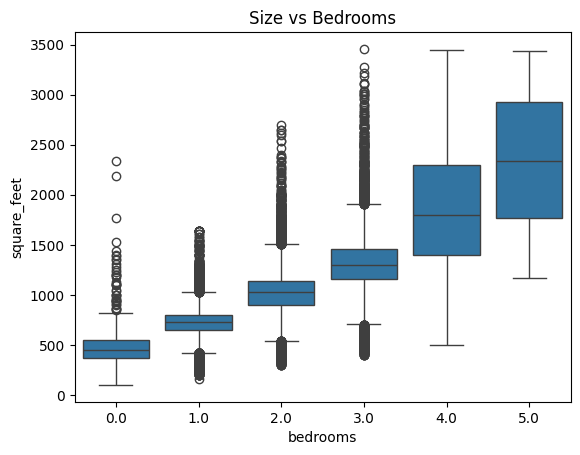

,count,mean,std,min,25%,50%,75%,max
bedrooms,,,,,,,,
0.0,470.0,501.182979,257.481977,101.0,365.0,449.5,550.0,2336.0
1.0,27993.0,727.266781,142.910090,156.0,650.0,726.0,802.0,1633.0
2.0,30439.0,1019.499031,217.068689,300.0,900.0,1033.0,1143.0,2700.0
3.0,6495.0,1315.868360,347.245513,400.0,1155.0,1302.0,1456.0,3456.0
4.0,681.0,1859.280470,609.410100,500.0,1400.0,1800.0,2300.0,3443.0
5.0,114.0,2338.403509,636.643267,1170.0,1766.5,2337.5,2926.5,3440.0


In [191]:
# remove extreme outliers
upper = df["square_feet"].quantile(0.999)
df = df[df["square_feet"] <= upper]
df = df[df["bedrooms"] <= 5] 
#df["bedrooms"] = df["bedrooms"].clip(upper=5)

sns.boxplot(x="bedrooms", y="square_feet", data=df)
plt.title("Size vs Bedrooms")
plt.show()

df.groupby("bedrooms")["square_feet"].describe()

In [192]:
df.shape

(66192, 26)

#### 'bathrooms'

In [193]:
df['bathrooms'].value_counts()

bathrooms
1.0    38248
2.0    27369
3.0      528
4.0       45
5.0        2
Name: count, dtype: int64

Due to the low frequency of properties with more than three bathrooms, these values were grouped into a “3+ bathrooms” category to improve model stability.

In [194]:
# grouping categories with more than 3 bathrooms into "3 or more bathrooms"
df["bathrooms"] = df["bathrooms"].clip(upper=3)

# convert to categorical
df["bathrooms"] = df["bathrooms"].astype("category")

# create dummy variables, reference category is 1 bathroom
df = pd.get_dummies(df, columns=["bathrooms"], drop_first=True)
df = df.astype({col: "int" for col in df.select_dtypes("bool").columns})

#### Log transform 'price' and 'square_feet'

The plot above shows that the distribution of the continuous variables 'price' and 'square_feet' are skewed to the right, so we conduct log transformation for them.

In [195]:
# remove invalid values

df = df[(df["price"] > 0) & (df["square_feet"] > 0)]
df = df.reset_index(drop=True)

# log transform

df["log_price"] = np.log(df["price"])

df["log_size"] = np.log(df["square_feet"])

In [196]:
continuous_cols = ["price", "square_feet", "log_price", "log_size"]

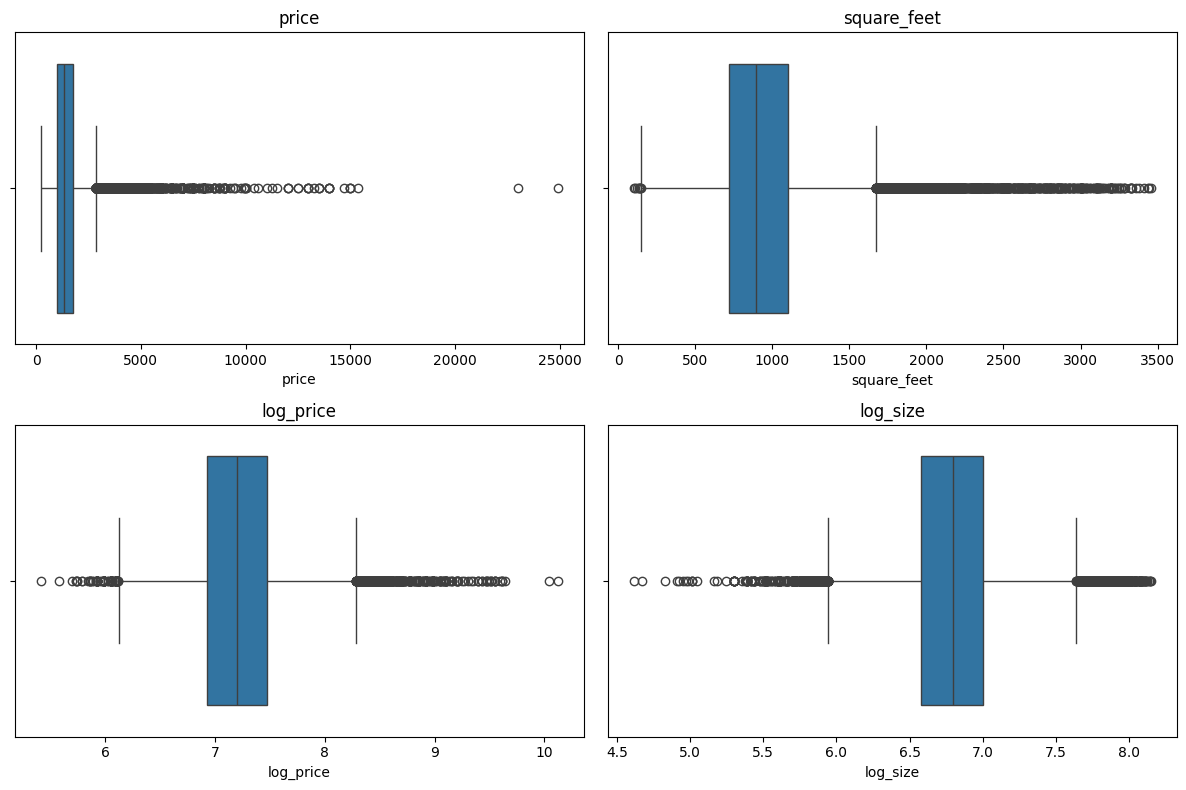

In [197]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(continuous_cols):
    ax = axes[i//2, i%2]
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

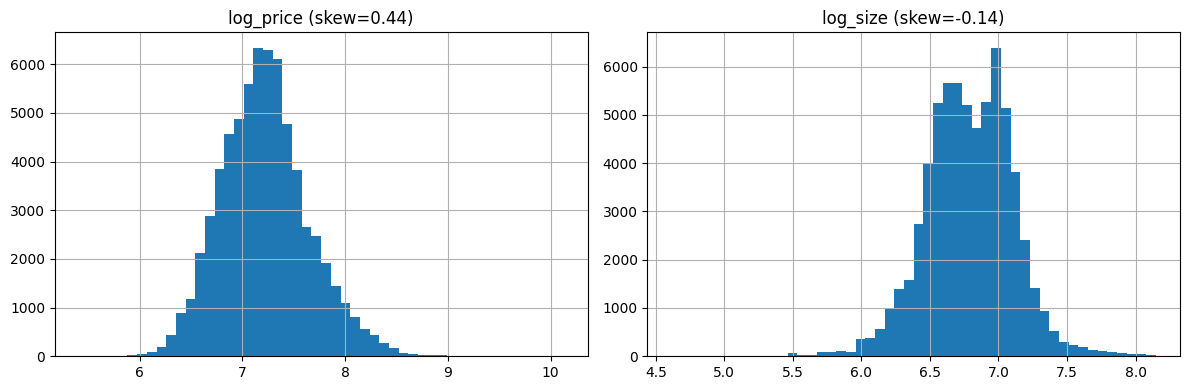

In [198]:
log_cols = ["log_price", "log_size"]

# Compute skewness
skew_vals = df[log_cols].skew()

# Create 1x2 grid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(log_cols):
    ax = axes[i]
    df[col].hist(bins=50, ax=ax)
    ax.set_title(f"{col} (skew={skew_vals[col]:.2f})")

plt.tight_layout()
plt.show()

In [199]:
df.columns

Index(['bedrooms', 'fee', 'price', 'square_feet', 'cityname',
       'pets_policy_no_pets', 'pets_policy_unknown', 'parking', 'pool', 'gym',
       'patio_deck', 'washer_dryer', 'storage', 'clubhouse', 'dishwasher',
       'ac', 'fireplace', 'refrigerator', 'cable_or_satellite', 'playground',
       'internet_access', 'amenities_missing', 'bathrooms_missing',
       'has_photo_Thumbnail', 'has_photo_No', 'bathrooms_2.0', 'bathrooms_3.0',
       'log_price', 'log_size'],
      dtype='str')

In [200]:
df.shape # 66192 instances, 29 variables

(66192, 29)

## Regression

How much should the rent be above/below the median price of the city it is located in?

### Linear Regression

In [201]:
# split into training and test sets, stratifying by city to ensure representation of all cities in both sets
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=451,
    stratify=df["cityname"]
)

# check the smallest amount of observations in a city in train and test sets
print(train_df["cityname"].value_counts().min())
print(test_df["cityname"].value_counts().min())

79
20


We store the median log-price for each city, so that we can use it for translating back into absolute prices. For new observations with new cities, we would use a global median.

In [202]:
# compute city and global medians on train set only to avoid data leakage
city_median_log_price = train_df.groupby("cityname")["log_price"].median()
global_median_log_price = train_df["log_price"].median()

The target variable is constructed by centering log prices around the city-level median, computed using the training data. This approach controls for systematic price differences across locations and avoids data leakage by ensuring that test observations are transformed using only information from the training set.

In [203]:
train_df["log_price_centered"] = (
    train_df["log_price"] - train_df["cityname"].map(city_median_log_price)
)

test_df["log_price_centered"] = (
    test_df["log_price"]
    - test_df["cityname"].map(city_median_log_price).fillna(global_median_log_price)
)

In [204]:
drop_cols = [
    "price",
    "square_feet",
    "cityname",
    "log_price",
    "log_price_centered"
]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["log_price_centered"]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df["log_price_centered"]

In [205]:
# Scale numerical features based on training set to avoid data leakage
scale_cols = ["log_size", "bedrooms"]
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
# Scale test set using the same scaler
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

In [206]:
# Fit linear regression model
linreg = LinearRegression()
linreg.fit(X_train, y_train)

# Predictions
y_train_pred_ols = linreg.predict(X_train)
y_test_pred_ols = linreg.predict(X_test)

# Evaluation
train_mse_ols = mean_squared_error(y_train, y_train_pred_ols)
test_mse_ols = mean_squared_error(y_test, y_test_pred_ols)

print(f"OLS intercept: {linreg.intercept_:.6f}")
print(f"Train MSE: {train_mse_ols:.6f}")
print(f"Test MSE: {test_mse_ols:.6f}")
print(f"Test RMSE: {np.sqrt(test_mse_ols):.6f}")
print(f"Test R²: {r2_score(y_test, y_test_pred_ols):.6f}")

OLS intercept: -0.031536
Train MSE: 0.058423
Test MSE: 0.058208
Test RMSE: 0.241263
Test R²: 0.361354


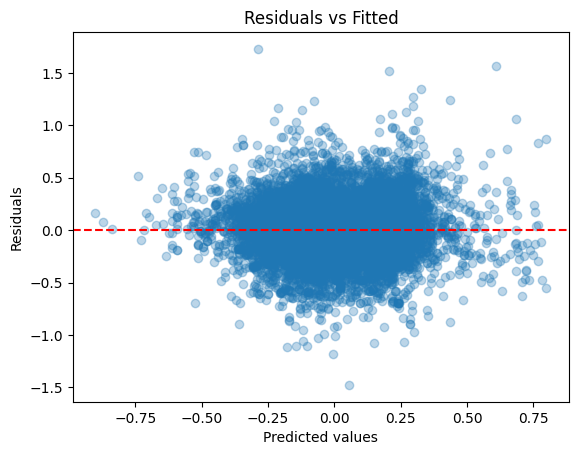

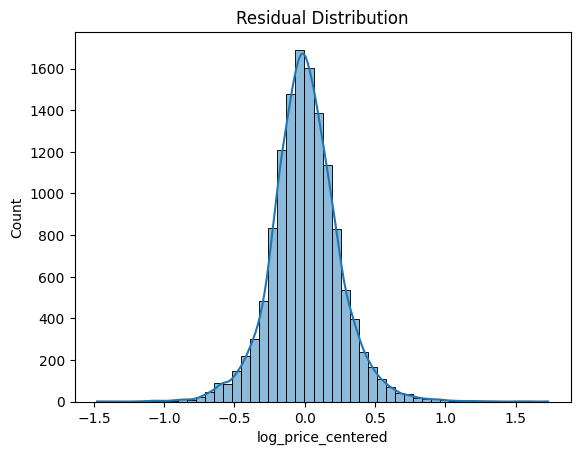

In [207]:
residuals = y_test - y_test_pred_ols

plt.scatter(y_test_pred_ols, residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

sns.histplot(residuals, bins=50, kde=True)
plt.title("Residual Distribution")
plt.show()

### Ridge and Lasso Regression Models

In [208]:
alphas = np.logspace(-5, 2, 100)

# Ridge regression with CV
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train, y_train)

ridge_train_pred = ridge_cv.predict(X_train)
ridge_test_pred = ridge_cv.predict(X_test)

ridge_results = pd.DataFrame({
    "Model": ["Ridge"],
    "Best Alpha": [ridge_cv.alpha_],
    "Train MSE": [mean_squared_error(y_train, ridge_train_pred)],
    "Test MSE": [mean_squared_error(y_test, ridge_test_pred)],
    "Test RMSE": [np.sqrt(mean_squared_error(y_test, ridge_test_pred))],
    "Test R²": [r2_score(y_test, ridge_test_pred)]
})

# Lasso regression with CV
lasso_cv = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=10000,
    random_state=451
)

lasso_cv.fit(X_train, y_train)

lasso_train_pred = lasso_cv.predict(X_train)
lasso_test_pred = lasso_cv.predict(X_test)

lasso_results = pd.DataFrame({
    "Model": ["Lasso"],
    "Best Alpha": [lasso_cv.alpha_],
    "Train MSE": [mean_squared_error(y_train, lasso_train_pred)],
    "Test MSE": [mean_squared_error(y_test, lasso_test_pred)],
    "Test RMSE": [np.sqrt(mean_squared_error(y_test, lasso_test_pred))],
    "Test R²": [r2_score(y_test, lasso_test_pred)]
})

regularisation_results = pd.concat(
    [ridge_results, lasso_results],
    ignore_index=True
)

regularisation_results

,Model,Best Alpha,Train MSE,Test MSE,Test RMSE,Test R²
0,Ridge,2.364489,0.058423,0.058207,0.241262,0.361358
1,Lasso,0.000010,0.058424,0.058208,0.241263,0.361355


In [209]:
from sklearn.model_selection import cross_val_score

ridge_cv_results = []

for a in alphas:

    ridge = Ridge(alpha=a)

    cv_mse = -cross_val_score(
        ridge,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    ).mean()

    ridge.fit(X_train, y_train)

    train_pred = ridge.predict(X_train)

    ridge_cv_results.append({
        "alpha": a,
        "trainMSE": mean_squared_error(y_train, train_pred),
        "cvMSE": cv_mse
    })

ridge_results_df = pd.DataFrame(ridge_cv_results)

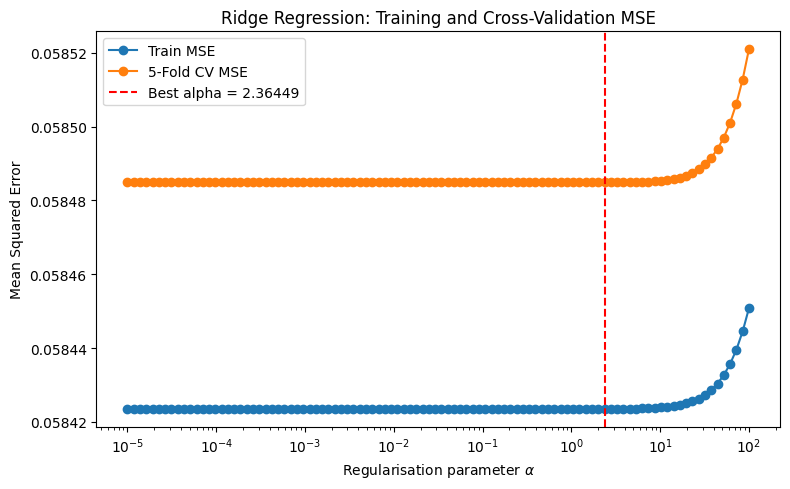

In [210]:
plt.figure(figsize=(8,5))

plt.plot(
    ridge_results_df["alpha"],
    ridge_results_df["trainMSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    ridge_results_df["alpha"],
    ridge_results_df["cvMSE"],
    marker="o",
    label="5-Fold CV MSE"
)

plt.axvline(
    ridge_cv.alpha_,
    color="red",
    linestyle="--",
    label=f"Best alpha = {ridge_cv.alpha_:.5f}"
)

plt.xscale("log")

plt.xlabel(r"Regularisation parameter $\alpha$")
plt.ylabel("Mean Squared Error")
plt.title("Ridge Regression: Training and Cross-Validation MSE")

plt.legend()

plt.tight_layout()
plt.show()

The training and test MSE are very close across all $\alpha$, with the train MSE slightly lower. This suggests that the model generalises well to unseen data. For large values of $\alpha$, both training and test errors increase, suggesting underfitting due to excessive shrinkage.

In [211]:
lasso_cv_results = []

for a in alphas:

    lasso = Lasso(alpha=a, max_iter=10000)

    cv_mse = -cross_val_score(
        lasso,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    ).mean()

    lasso.fit(X_train, y_train)

    train_pred = lasso.predict(X_train)

    lasso_cv_results.append({
        "alpha": a,
        "trainMSE": mean_squared_error(y_train, train_pred),
        "cvMSE": cv_mse
    })

lasso_results_df = pd.DataFrame(lasso_cv_results)

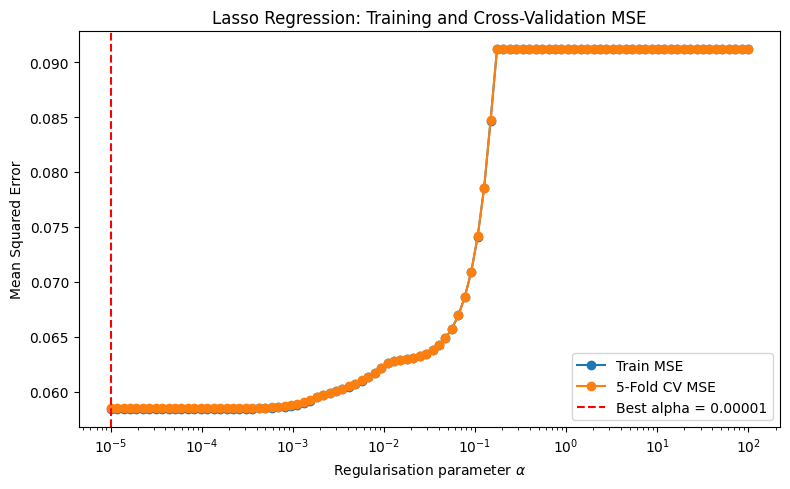

In [212]:
plt.figure(figsize=(8,5))

plt.plot(
    lasso_results_df["alpha"],
    lasso_results_df["trainMSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    lasso_results_df["alpha"],
    lasso_results_df["cvMSE"],
    marker="o",
    label="5-Fold CV MSE"
)

plt.axvline(
    lasso_cv.alpha_,
    color="red",
    linestyle="--",
    label=f"Best alpha = {lasso_cv.alpha_:.5f}"
)

plt.xscale("log")

plt.xlabel(r"Regularisation parameter $\alpha$")
plt.ylabel("Mean Squared Error")
plt.title("Lasso Regression: Training and Cross-Validation MSE")

plt.legend()

plt.tight_layout()
plt.show()

Similar to Ridge regression, the training and test MSE are very close across all $\alpha$. This suggests that the model generalises well to unseen data. For larger values of $\alpha$, both training and test errors increase substanstially, suggesting underfitting due to excessive shrinkage.

### Bayesian Linear Regression

Bayesian linear regression is implemented using a Normal likelihood and a Normal prior on the regression coefficients. The prior aims to shrink coefficients toward zero, similarly to Ridge regression. Posterior means are used as point estimates.

In [213]:
# Function adapted from ST451 Week 3 Seminar

# Posterior summaries were obtained using Monte Carlo sampling. Variance parameters were sampled from the inverse-gamma posterior, and regression coefficients were sampled from the conditional normal posterior. These samples were then used to estimate posterior means and 95% credible intervals.

def BLR(X, y, mu_0, Om_0_inv, a_0, b_0, ind_names, N):
    col_names = ['posterior mean', 'lower 95% bound', 'upper 95% bound']
    
    n, p = X.shape
    
    XtX = X.T.dot(X)
    Om_n_inv = XtX + Om_0_inv
    Om_n = sc.linalg.inv(Om_n_inv)
    
    term1 = Om_0_inv.dot(mu_0) + X.T.dot(y)
    mu_n = Om_n.dot(term1)
    
    a_n = a_0 + n / 2
    
    term2 = (
        y.T.dot(y)
        + mu_0.dot(Om_0_inv.dot(mu_0))
        - mu_n.dot(Om_n_inv.dot(mu_n))
    )
    
    b_n = b_0 + term2 / 2
    
    sigma2 = 1 / np.random.gamma(a_n, 1 / b_n, N)
    
    betas = np.zeros((N, p))
    
    for i in range(N):
        cov = sigma2[i] * Om_n
        betas[i, :] = np.random.multivariate_normal(mu_n, cov)
    
    mu_beta = np.mean(betas, axis=0)
    lower95 = np.percentile(betas, 2.5, axis=0)
    upper95 = np.percentile(betas, 97.5, axis=0)
    
    results = np.column_stack([mu_beta, lower95, upper95])
    results = pd.DataFrame(results, columns=col_names, index=ind_names)
    
    return results, mu_n, Om_n, a_n, b_n

In [214]:
Xtr = X_train.to_numpy()
Xte = X_test.to_numpy()
ytr = y_train.to_numpy()
yte = y_test.to_numpy()

# Add intercept
Xtr_bayes = np.column_stack([np.ones(Xtr.shape[0]), Xtr])
Xte_bayes = np.column_stack([np.ones(Xte.shape[0]), Xte])

ind_names = ["x0"] + list(X_train.columns)

n, p = Xtr_bayes.shape

mu_0 = np.zeros(p)

XtX = Xtr_bayes.T.dot(Xtr_bayes)
Om_0_inv = XtX / n   # unit information prior

a_0 = 0.01
b_0 = 0.01

N = 10000

np.random.seed(451)

bayes_results, mu_n, Om_n, a_n, b_n = BLR(
    Xtr_bayes,
    ytr,
    mu_0,
    Om_0_inv,
    a_0,
    b_0,
    ind_names,
    N
)

bayes_results

,posterior mean,lower 95% bound,upper 95% bound
x0,-0.031508,-0.038063,-0.024891
bedrooms,-0.019477,-0.022563,-0.016379
fee,-0.042409,-0.090595,0.005452
pets_policy_no_pets,-0.008824,-0.020154,0.002533
pets_policy_unknown,-0.022466,-0.027136,-0.017935
parking,0.039914,0.035255,0.044474
pool,0.016437,0.011406,0.021428
gym,0.036754,0.031566,0.042082
patio_deck,-0.003150,-0.008509,0.002259
washer_dryer,-0.016026,-0.021441,-0.010597


In [215]:
y_pred_bayes = Xte_bayes @ mu_n

mse_bayes = mean_squared_error(yte, y_pred_bayes)
rmse_bayes = np.sqrt(mse_bayes)
r2_bayes = r2_score(yte, y_pred_bayes)

print(f"Bayesian Linear Regression MSE: {mse_bayes:.6f}")
print(f"Bayesian Linear Regression RMSE: {rmse_bayes:.6f}")
print(f"Bayesian Linear Regression R²: {r2_bayes:.6f}")

Bayesian Linear Regression MSE: 0.058208
Bayesian Linear Regression RMSE: 0.241263
Bayesian Linear Regression R²: 0.361354


Bayesian linear regression produced identical predictive performance to OLS, Ridge and Lasso. This was expected because the training sample is large and the unit information prior is weak, so the likelihood dominates the prior. As a result, the posterior mean is very close to the OLS estimate.

Bootstrap resampling is used to assess the stability of the model’s predictive performance. 

In [216]:
B = 500
bootstrap_results = []

np.random.seed(451)

for b in range(B):
    # resample training rows with replacement
    sample_idx = np.random.choice(X_train.index, size=len(X_train), replace=True)

    X_boot = X_train.loc[sample_idx]
    y_boot = y_train.loc[sample_idx]

    model_boot = LinearRegression()
    model_boot.fit(X_boot, y_boot)

    test_pred = model_boot.predict(X_test)

    bootstrap_results.append({
        "bootstrap": b,
        "testMSE": mean_squared_error(y_test, test_pred),
        "testRMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "testR2": r2_score(y_test, test_pred)
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

bootstrap_df.describe()

,bootstrap,testMSE,testRMSE,testR2
count,500.000000,500.000000,500.000000,500.000000
mean,249.500000,0.058239,0.241328,0.361008
std,144.481833,0.000028,0.000057,0.000303
min,0.000000,0.058167,0.241179,0.359739
25%,124.750000,0.058221,0.241290,0.360844
50%,249.500000,0.058237,0.241324,0.361032
75%,374.250000,0.058254,0.241359,0.361210
max,499.000000,0.058355,0.241568,0.361798


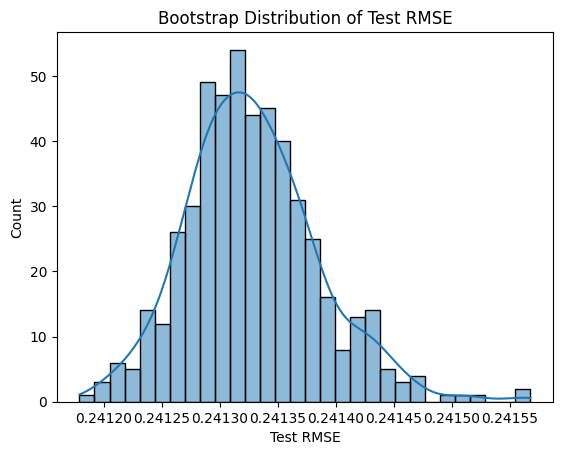

In [217]:
sns.histplot(bootstrap_df["testRMSE"], bins=30, kde=True)
plt.title("Bootstrap Distribution of Test RMSE")
plt.xlabel("Test RMSE")
plt.show()

In [218]:
bootstrap_df["testRMSE"].quantile([0.025, 0.5, 0.975])

0.025    0.241225
0.500    0.241324
0.975    0.241450
Name: testRMSE, dtype: float64

From the outputs we can conclude that the model is very stable and that the observed performance is not sensitive to sampling variation.

### Sample Size Effect

In [219]:
sample_sizes = [20, 50, 100, 200, 500, 1000, 2000, 10000, 20000]

sample_results = []

np.random.seed(451)

alphas = np.logspace(-5, 2, 100)

for n_sample in sample_sizes:

    sample_idx = np.random.choice(
        X_train.index,
        size=n_sample,
        replace=False
    )

    X_small = X_train.loc[sample_idx]
    y_small = y_train.loc[sample_idx]

    # OLS
    ols_small = LinearRegression()

    ols_small.fit(X_small, y_small)

    ols_pred = ols_small.predict(X_test)

    # Ridge Regression
    ridge_cv_small = RidgeCV(
        alphas=alphas,
        cv=3
    )

    ridge_cv_small.fit(X_small, y_small)

    ridge_pred = ridge_cv_small.predict(X_test)

    # Lasso Regression
    lasso_cv_small = LassoCV(
        alphas=alphas,
        cv=3,
        max_iter=10000,
        random_state=451
    )

    lasso_cv_small.fit(X_small, y_small)

    lasso_pred = lasso_cv_small.predict(X_test)

    # Bayesian Linear Regression
    Xtr_small = X_small.to_numpy()
    Xte_full = X_test.to_numpy()
    ytr_small = y_small.to_numpy()

    Xtr_small_bayes = np.column_stack([
        np.ones(Xtr_small.shape[0]),
        Xtr_small
    ])

    Xte_full_bayes = np.column_stack([
        np.ones(Xte_full.shape[0]),
        Xte_full
    ])

    ind_names_small = ["x0"] + list(X_small.columns)

    n, p = Xtr_small_bayes.shape

    mu_0 = np.zeros(p)

    XtX = Xtr_small_bayes.T @ Xtr_small_bayes

    Om_0_inv = XtX / n + 1e-6 * np.eye(p)

    bayes_res, mu_n_small, Om_n, a_n, b_n = BLR(
        Xtr_small_bayes,
        ytr_small,
        mu_0,
        Om_0_inv,
        a_0=0.01,
        b_0=0.01,
        ind_names=ind_names_small,
        N=5000
    )

    bayes_pred = Xte_full_bayes @ mu_n_small

    # Store results
    sample_results.append({

        "sample_size": n_sample,

        "OLS_MSE": mean_squared_error(y_test, ols_pred),
        "OLS_RMSE": np.sqrt(mean_squared_error(y_test, ols_pred)),
        "OLS_R2": r2_score(y_test, ols_pred),

        "Ridge_alpha": ridge_cv_small.alpha_,
        "Ridge_MSE": mean_squared_error(y_test, ridge_pred),
        "Ridge_RMSE": np.sqrt(mean_squared_error(y_test, ridge_pred)),
        "Ridge_R2": r2_score(y_test, ridge_pred),

        "Lasso_alpha": lasso_cv_small.alpha_,
        "Lasso_MSE": mean_squared_error(y_test, lasso_pred),
        "Lasso_RMSE": np.sqrt(mean_squared_error(y_test, lasso_pred)),
        "Lasso_R2": r2_score(y_test, lasso_pred),

        "Bayesian_MSE": mean_squared_error(y_test, bayes_pred),
        "Bayesian_RMSE": np.sqrt(mean_squared_error(y_test, bayes_pred)),
        "Bayesian_R2": r2_score(y_test, bayes_pred)
    })

sample_results_df = pd.DataFrame(sample_results)

sample_results_df

,sample_size,OLS_MSE,OLS_RMSE,OLS_R2,Ridge_alpha,Ridge_MSE,Ridge_RMSE,Ridge_R2,Lasso_alpha,Lasso_MSE,Lasso_RMSE,Lasso_R2,Bayesian_MSE,Bayesian_RMSE,Bayesian_R2
0,20,0.228305,0.477813,-1.504928,2.364489,0.076174,0.275997,0.164229,0.024771,0.068027,0.260820,0.253621,0.214969,0.463648,-1.358607
1,50,0.102004,0.319380,-0.119169,8.697490,0.064178,0.253334,0.295848,0.009326,0.064174,0.253326,0.295892,0.100224,0.316581,-0.099637
2,100,0.088536,0.297550,0.028597,23.101297,0.062670,0.250339,0.312401,0.040370,0.064235,0.253447,0.295223,0.087901,0.296481,0.035567
3,200,0.069241,0.263137,0.240297,23.101297,0.063232,0.251460,0.306230,0.015199,0.063765,0.252517,0.300384,0.069178,0.263017,0.240992
4,500,0.062181,0.249360,0.317766,37.649358,0.061315,0.247618,0.327266,0.002535,0.060780,0.246536,0.333133,0.062179,0.249357,0.317783
5,1000,0.060190,0.245336,0.339608,10.235310,0.059903,0.244752,0.342751,0.000689,0.059838,0.244619,0.343463,0.060183,0.245323,0.339677
6,2000,0.059149,0.243207,0.351022,14.174742,0.059244,0.243401,0.349984,0.000498,0.059157,0.243223,0.350936,0.059148,0.243203,0.351042
7,10000,0.058376,0.241611,0.359511,2.364489,0.058377,0.241614,0.359496,0.000010,0.058375,0.241608,0.359524,0.058376,0.241611,0.359512
8,20000,0.058250,0.241350,0.360893,4.534879,0.058247,0.241345,0.360920,0.000010,0.058249,0.241347,0.360906,0.058250,0.241350,0.360893


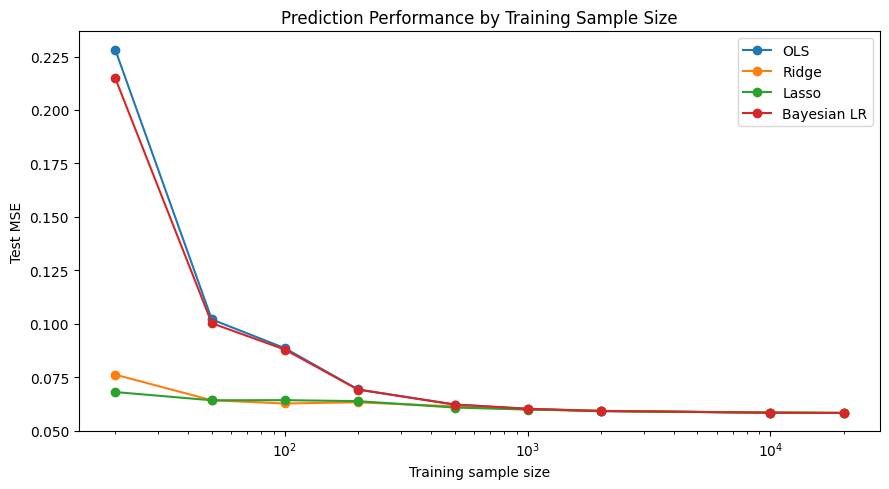

In [220]:
plt.figure(figsize=(9,5))

plt.plot(
    sample_results_df["sample_size"],
    sample_results_df["OLS_MSE"],
    marker="o",
    label="OLS"
)

plt.plot(
    sample_results_df["sample_size"],
    sample_results_df["Ridge_MSE"],
    marker="o",
    label="Ridge"
)

plt.plot(
    sample_results_df["sample_size"],
    sample_results_df["Lasso_MSE"],
    marker="o",
    label="Lasso"
)

plt.plot(
    sample_results_df["sample_size"],
    sample_results_df["Bayesian_MSE"],
    marker="o",
    label="Bayesian LR"
)

plt.xscale("log")

plt.xlabel("Training sample size")
plt.ylabel("Test MSE")

plt.title("Prediction Performance by Training Sample Size")

plt.legend()

plt.tight_layout()
plt.show()

We can see that although Ridge and Lasso perform better in smaller samples, their advantage disappears as the sample size increases. When the training data sample size is larger than 1000, all four models achieve nearly identical predictive performance. Therefore, Bayesian linear regression is used for the subsequent coefficient interpretation because it provides posterior uncertainty through credible intervals while maintaining comparable predictive performance to OLS, Ridge, and Lasso.

### Interpretation of Coefficients in a Log-Linear Model

The regression model is specified as:

$$
\log(y) = \beta_0 + \beta_1 x_1 + \cdots + \beta_k x_k.
$$

If there is an increase in a predictor $x_j$ by 1 unit, then the change in the dependent variable in log terms is:

$$
\log(y_{\text{new}}) - \log(y_{\text{old}}) = \beta_j
$$

$$
\log\left(\frac{y_{\text{new}}}{y_{\text{old}}}\right) = \beta_j
$$

$$
\frac{y_{\text{new}}}{y_{\text{old}}} = e^{\beta_j}
$$

$$
y_{\text{new}} = y_{\text{old}} \cdot e^{\beta_j}
$$

Therefore, the proportional change in \( y \) is:

$$
\frac{y_{\text{new}} - y_{\text{old}}}{y_{\text{old}}} = e^{\beta_j} - 1
$$

Thus, the percentage change is:

$$
\text{Percentage change} = (e^{\beta_j} - 1) \times 100
$$

In [221]:
# Convert Bayesian posterior summaries to percentage effects
bayes_results_pct = bayes_results.copy()

bayes_results_pct["percent_effect"] = (
    np.exp(bayes_results_pct["posterior mean"]) - 1
) * 100

bayes_results_pct["lower 95% percent"] = (
    np.exp(bayes_results_pct["lower 95% bound"]) - 1
) * 100

bayes_results_pct["upper 95% percent"] = (
    np.exp(bayes_results_pct["upper 95% bound"]) - 1
) * 100

# Sort by decreasing absolute posterior mean, so the largest effects appear first
bayes_results_pct = bayes_results_pct.sort_values(
    by="posterior mean",
    key=abs,
    ascending=False
)

bayes_results_pct

,posterior mean,lower 95% bound,upper 95% bound,percent_effect,lower 95% percent,upper 95% percent
bathrooms_3.0,0.279958,0.255769,0.304400,32.307419,29.145475,35.581183
log_size,0.152149,0.149010,0.155340,16.433358,16.068444,16.805532
playground,-0.110100,-0.117131,-0.102946,-10.425572,-11.053109,-9.782422
bathrooms_2.0,0.087617,0.081378,0.094003,9.156960,8.478076,9.856309
bathrooms_missing,-0.060780,-0.070772,-0.050692,-5.896946,-6.832533,-4.942870
ac,-0.042618,-0.049401,-0.035694,-4.172290,-4.820049,-3.506495
fee,-0.042409,-0.090595,0.005452,-4.152266,-8.661281,0.546685
parking,0.039914,0.035255,0.044474,4.072132,3.588382,4.547772
gym,0.036754,0.031566,0.042082,3.743820,3.206934,4.297975
amenities_missing,0.033368,0.026592,0.040444,3.393145,2.694908,4.127351


Interpretation of percentages: 

Since the dependent variable is the log of price relative to the city median, coefficients can be interpreted as percentage changes in rent relative to the city median, keeping other variables constant.

As some variables are standardised or regroupped with respect to a reference group, we consider these differences in the interpretation: 

- Binary variables with a reference group:

    Example: bathrooms_2.0 and bathrooms_3.0 are compared to the reference group: 1 bathroom, so a property with 3 or more bathrooms has about 32.3% higher and a property with 2 bathrooms has about 8.5% higher relative rent than 1-bathroom listings.

- Standardised variables:

    Example: log_size: 1 standard deviation increase in log size is associated with about 16.4% higher relative rent.

- Binary variables:

    Example: playground: Listings with playground mentioned have about 10.4% lower rent relative to the city median compared to listings without a playground.

The Bayesian regression results indicate that property characteristics have economically meaningful effects on rental prices relative to the city median.

Listings with three or more bathrooms are associated with approximately 32.3% higher rents compared to one-bathroom properties (95% credible interval: 29%–36%). Similarly, a one standard deviation increase in log size is associated with around 16.1% higher rents, highlighting the importance of property size.

In contrast, certain amenities are associated with lower relative prices. For example, listings mentioning playground as amenity have rents approximately 10.4% lower than other properties. Missing bathroom information is also associated with a 6.8% decrease in rent, suggesting that incomplete listings may signal lower-quality properties.

Some features, such as parking and gym, have smaller positive effects (around 4.1% and 3.7% respectively), with narrow credible intervals indicating strong evidence. However, other variables, such as the variable fee shows uncertain effect, as its credible interval includes zero.

## Cluster Analysis

The objective of the clustering analysis is to explore the underlying structure of the data and to identify potential market segments (submarkets), and analyse how rental prices differ across these segments.

### Gaussian Mixture Model

The following features are selected because they capture the key structural characteristics of rental properties: size and layout. These are the key drivers of heterogeneity in the housing market and therefore most relevant for identifying meaningful rental submarkets.

In [222]:
cluster_features = [
    "log_size",
    "bedrooms",
    "bathrooms_2.0",
    "bathrooms_3.0"
]

The Bayesian GMM was fitted on the training data only to avoid information leakage. 

In [223]:
X_cluster_train = train_df[cluster_features].copy()
X_cluster_test = test_df[cluster_features].copy()

cluster_scaler = StandardScaler()
X_cluster_train_scaled = cluster_scaler.fit_transform(X_cluster_train)
X_cluster_test_scaled = cluster_scaler.transform(X_cluster_test)

bgmm = BayesianGaussianMixture(
    n_components=8,
    covariance_type="full",
    weight_concentration_prior=0.01,
    max_iter=500,
    random_state=451
)

bgmm.fit(X_cluster_train_scaled)

train_df["bayes_cluster"] = bgmm.predict(X_cluster_train_scaled)
test_df["bayes_cluster"] = bgmm.predict(X_cluster_test_scaled)

Gaussian mixture models with different numbers of components and covariance structures are compared using BIC.

In [224]:
lowest_bic = np.inf

n_components_range = range(1, 9)
cv_types = ["spherical", "tied", "diag", "full"]

bic = np.zeros((len(n_components_range), len(cv_types)))

best_gmm = None

for j, cv_type in enumerate(cv_types):
    for i, n_components in enumerate(n_components_range):

        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type=cv_type,
            random_state=451
        )

        gmm.fit(X_cluster_train_scaled)

        bic_ij = gmm.bic(X_cluster_train_scaled)
        bic[i, j] = bic_ij

        if bic_ij < lowest_bic:
            lowest_bic = bic_ij
            best_gmm = gmm

bic_df = pd.DataFrame(
    bic,
    columns=cv_types,
    index=n_components_range
).round(0)

print(f"Lowest BIC: {lowest_bic:,.0f}")
print("Best number of clusters:", best_gmm.n_components)
print("Best covariance type:", best_gmm.covariance_type)

bic_df

Lowest BIC: -1,578,274
Best number of clusters: 8
Best covariance type: full


,spherical,tied,diag,full
1,601151.0,522309.0,601183.0,522309.0
2,538422.0,-256928.0,-189639.0,-263442.0
3,393856.0,-195932.0,-621865.0,-910378.0
4,237418.0,-977155.0,-1248708.0,-1257616.0
5,265245.0,-983181.0,-1342529.0,-1262482.0
6,172663.0,-1014892.0,-1568993.0,-1482088.0
7,123887.0,-1014838.0,-1570216.0,-1487941.0
8,53361.0,-1046366.0,-1577707.0,-1578274.0


In [225]:
# Hard cluster allocation
train_df["bayes_cluster"] = gmm.predict(X_cluster_train_scaled)
test_df["bayes_cluster"] = gmm.predict(X_cluster_test_scaled)

# Posterior probabilities / soft allocation
train_probs = gmm.predict_proba(X_cluster_train_scaled)
test_probs = gmm.predict_proba(X_cluster_test_scaled)

In [226]:
# Cluster sizes (soft allocation)
train_soft_sizes = pd.Series(
    train_probs.sum(axis=0).round(0).astype(int),
    name="soft size"
)

train_hard_sizes = train_df["bayes_cluster"].value_counts().sort_index()

cluster_sizes = pd.DataFrame({
    "hard size": train_hard_sizes,
    "soft size": train_soft_sizes
}).fillna(0).astype(int)

cluster_sizes

,hard size,soft size
0,4202,7514
1,22239,22239
2,455,455
3,4648,4649
4,7086,7086
5,877,877
6,13060,9747
7,386,386


<!-- train_df["bayes_cluster"] = best_gmm.predict(X_cluster_train_scaled)
test_df["bayes_cluster"] = best_gmm.predict(X_cluster_test_scaled) -->

A Gaussian Mixture Model was implemented with the number of components selected using the Bayesian Information Criterion (BIC). However, this approach requires specifying the number of clusters in advance and may allocate observations to all components even when some are not supported by the data. To address this limitation, a Bayesian Gaussian Mixture Model was estimated using a component number larger than the features used and a Dirichlet prior on cluster weights. The prior penalises unnecessary components by assigning them very small weights, allowing the effective number of clusters to be determined by the data.

### Bayesian Gaussian Mixture Model

Since BIC-based GMM model search was conducted over K=1,$\dots$,8, K=8 was used as the maximum number of components in the Bayesian GMM. 

In [227]:
bgmm = BayesianGaussianMixture(
    n_components=best_gmm.n_components,
    covariance_type="full",
    weight_concentration_prior=0.01,
    max_iter=500,
    random_state=451
)

bgmm.fit(X_cluster_train_scaled)

# Hard cluster allocation
train_df["bayes_cluster"] = bgmm.predict(X_cluster_train_scaled)
test_df["bayes_cluster"] = bgmm.predict(X_cluster_test_scaled)

# store posterior probabilities
train_probs = bgmm.predict_proba(X_cluster_train_scaled)
test_probs = bgmm.predict_proba(X_cluster_test_scaled)

In [228]:
# Cluster sizes (soft allocation)
train_soft_sizes = pd.Series(
    train_probs.sum(axis=0).round(0).astype(int),
    name="soft size"
)

train_hard_sizes = train_df["bayes_cluster"].value_counts().sort_index()

cluster_sizes = pd.DataFrame({
    "hard size": train_hard_sizes,
    "soft size": train_soft_sizes
}).fillna(0).astype(int)

cluster_sizes

,hard size,soft size
0,17251,17248
1,22239,22239
2,455,455
3,4659,4662
4,7086,7086
5,877,877
6,0,0
7,386,386


Cluster sizes are computed using both hard and soft assignments. Hard assignments allocate each listing to a single cluster, and soft allocation uses posterior probabilities to reflect uncertainty in cluster membership. The similarity between hard and soft cluster sizes suggests that the Bayesian GMM assigns observations to clusters with high certainty, indicating well-separated groups.  One component received zero weight, suggesting that the data support a 7-cluster structure rather than the full 8-component specification.

Test observations were assigned to the learned clusters using the highest posterior membership probability.

In [229]:
# Remove cluster with 0 weight
cluster_sizes_soft = pd.Series(
    train_probs.sum(axis=0),
    index=range(bgmm.n_components)
)

active_clusters = cluster_sizes_soft[
    cluster_sizes_soft >= 1
].index

train_df = train_df[
    train_df["bayes_cluster"].isin(active_clusters)
].copy()

test_df = test_df[
    test_df["bayes_cluster"].isin(active_clusters)
].copy()

In [230]:
# Cluster profiling on training data
cluster_summary = train_df.groupby("bayes_cluster")[cluster_features].mean()

cluster_summary_with_price = cluster_summary.copy()

cluster_summary_with_price["log_price_centered"] = (
    train_df.groupby("bayes_cluster")["log_price_centered"].mean()
)

cluster_summary_pct = cluster_summary_with_price.copy()

cluster_summary_pct["price_%_vs_city_median"] = (
    np.exp(cluster_summary_pct["log_price_centered"]) - 1
) * 100

cluster_summary_pct["approx_size_sqft"] = np.exp(cluster_summary_pct["log_size"])

cluster_summary_pct

,log_size,bedrooms,bathrooms_2.0,bathrooms_3.0,log_price_centered,price_%_vs_city_median,approx_size_sqft
bayes_cluster,,,,,,,
0,6.989821,2.000000,1.0,0.0,0.140524,15.087663,1085.527008
1,6.566975,1.000000,0.0,0.0,-0.097699,-9.307812,711.215428
2,7.494333,3.391209,0.0,1.0,0.533304,70.455495,1797.825552
3,7.217318,3.023181,1.0,0.0,0.233232,26.267410,1362.829161
4,6.685618,2.000000,0.0,0.0,-0.122321,-11.513577,800.805113
5,6.792906,3.123147,0.0,0.0,-0.034177,-3.359951,891.500721
7,6.117558,0.000000,0.0,0.0,-0.360598,-30.274064,453.755462


Cluster profiling is conducted using variables not included in the clustering process, allowing interpretation of clusters in terms of listing characteristics. This provides additional insights into the economic meaning of each segment.

In [231]:
exclude_from_profile = [
    "price", "square_feet", "log_price", "log_price_centered",
    "log_size", "cityname",
    "bedrooms", "bathrooms_2.0", "bathrooms_3.0",
    "bayes_cluster"
]

binary_profile_cols = [
    col for col in train_df.columns
    if col not in exclude_from_profile
    and train_df[col].nunique() == 2
]

cluster_binary_profile = (
    train_df
    .groupby("bayes_cluster")[binary_profile_cols]
    .mean()
)

cluster_binary_profile

,fee,pets_policy_no_pets,pets_policy_unknown,parking,pool,gym,patio_deck,washer_dryer,storage,clubhouse,dishwasher,ac,fireplace,refrigerator,cable_or_satellite,playground,internet_access,amenities_missing,bathrooms_missing,has_photo_Thumbnail,has_photo_No
bayes_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.000870,0.019013,0.587038,0.474523,0.505246,0.451568,0.278361,0.300562,0.241551,0.233726,0.138948,0.144977,0.189438,0.118892,0.114254,0.115588,0.115703,0.133615,0.086604,0.329952,0.098139
1,0.001304,0.041549,0.545978,0.452448,0.469266,0.403750,0.261702,0.254193,0.231665,0.193489,0.156842,0.142677,0.164531,0.142722,0.124466,0.089078,0.124691,0.157201,0.014119,0.349026,0.098251
2,0.004396,0.076923,0.593407,0.349451,0.274725,0.226374,0.261538,0.232967,0.112088,0.107692,0.167033,0.129670,0.200000,0.162637,0.103297,0.057143,0.068132,0.261538,0.039560,0.353846,0.090110
3,0.003005,0.044001,0.565143,0.398583,0.423696,0.358446,0.265078,0.281820,0.204121,0.206482,0.174501,0.144237,0.174716,0.147671,0.107319,0.154325,0.098090,0.183086,0.148530,0.349217,0.085641
4,0.002822,0.056026,0.550522,0.425487,0.355490,0.286339,0.253034,0.235111,0.191081,0.132797,0.194045,0.199831,0.111064,0.180638,0.132233,0.127858,0.097093,0.165538,0.000000,0.360711,0.095258
5,0.014823,0.096921,0.549601,0.388826,0.216648,0.151653,0.245154,0.180160,0.165336,0.053592,0.177879,0.117446,0.059293,0.192702,0.102623,0.077537,0.074116,0.209806,0.000000,0.334094,0.117446
7,0.010363,0.183938,0.401554,0.297927,0.106218,0.088083,0.103627,0.069948,0.103627,0.046632,0.147668,0.145078,0.018135,0.297927,0.178756,0.002591,0.163212,0.341969,0.031088,0.569948,0.077720


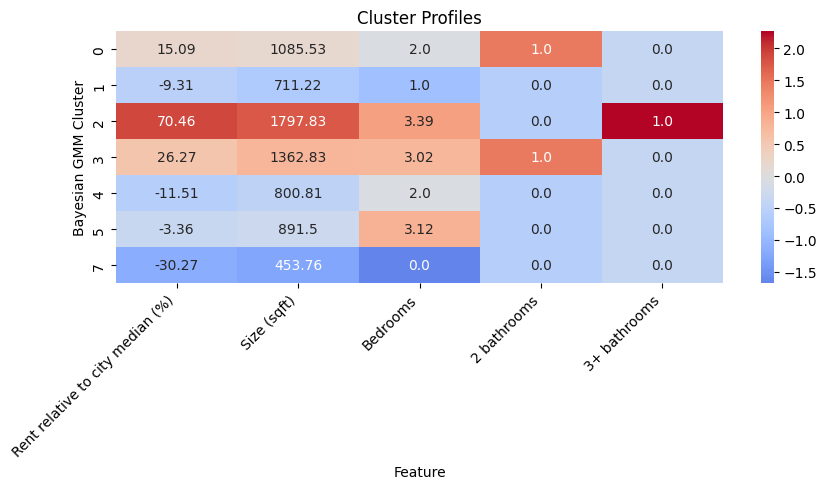

In [232]:
# plot structural profile heatmap

cluster_summary_plot = cluster_summary_pct[
    [
        "price_%_vs_city_median",
        "approx_size_sqft",
        "bedrooms",
        "bathrooms_2.0",
        "bathrooms_3.0"
    ]
].rename(columns={
    "price_%_vs_city_median": "Rent relative to city median (%)",
    "approx_size_sqft": "Size (sqft)",
    "bedrooms": "Bedrooms",
    "bathrooms_2.0": "2 bathrooms",
    "bathrooms_3.0": "3+ bathrooms"
})

cluster_summary_heatmap = (
    cluster_summary_plot - cluster_summary_plot.mean()
) / cluster_summary_plot.std()

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_summary_heatmap,
    annot=cluster_summary_plot.round(2),
    fmt="",
    cmap="coolwarm",
    center=0
)

plt.title("Cluster Profiles")
plt.xlabel("Feature")
plt.ylabel("Bayesian GMM Cluster")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [233]:
# Binary feature profile

exclude_from_profile = [
    "price", "square_feet", "log_price", "log_price_centered",
    "log_size", "cityname",
    "bedrooms", "bathrooms_2.0", "bathrooms_3.0",
    "bayes_cluster"
]

binary_profile_cols = [
    col for col in train_df.columns
    if col not in exclude_from_profile
    and train_df[col].nunique() == 2
]

cluster_binary_profile = (
    train_df
    .groupby("bayes_cluster")[binary_profile_cols]
    .mean()
)

cluster_binary_profile

,fee,pets_policy_no_pets,pets_policy_unknown,parking,pool,gym,patio_deck,washer_dryer,storage,clubhouse,dishwasher,ac,fireplace,refrigerator,cable_or_satellite,playground,internet_access,amenities_missing,bathrooms_missing,has_photo_Thumbnail,has_photo_No
bayes_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.000870,0.019013,0.587038,0.474523,0.505246,0.451568,0.278361,0.300562,0.241551,0.233726,0.138948,0.144977,0.189438,0.118892,0.114254,0.115588,0.115703,0.133615,0.086604,0.329952,0.098139
1,0.001304,0.041549,0.545978,0.452448,0.469266,0.403750,0.261702,0.254193,0.231665,0.193489,0.156842,0.142677,0.164531,0.142722,0.124466,0.089078,0.124691,0.157201,0.014119,0.349026,0.098251
2,0.004396,0.076923,0.593407,0.349451,0.274725,0.226374,0.261538,0.232967,0.112088,0.107692,0.167033,0.129670,0.200000,0.162637,0.103297,0.057143,0.068132,0.261538,0.039560,0.353846,0.090110
3,0.003005,0.044001,0.565143,0.398583,0.423696,0.358446,0.265078,0.281820,0.204121,0.206482,0.174501,0.144237,0.174716,0.147671,0.107319,0.154325,0.098090,0.183086,0.148530,0.349217,0.085641
4,0.002822,0.056026,0.550522,0.425487,0.355490,0.286339,0.253034,0.235111,0.191081,0.132797,0.194045,0.199831,0.111064,0.180638,0.132233,0.127858,0.097093,0.165538,0.000000,0.360711,0.095258
5,0.014823,0.096921,0.549601,0.388826,0.216648,0.151653,0.245154,0.180160,0.165336,0.053592,0.177879,0.117446,0.059293,0.192702,0.102623,0.077537,0.074116,0.209806,0.000000,0.334094,0.117446
7,0.010363,0.183938,0.401554,0.297927,0.106218,0.088083,0.103627,0.069948,0.103627,0.046632,0.147668,0.145078,0.018135,0.297927,0.178756,0.002591,0.163212,0.341969,0.031088,0.569948,0.077720


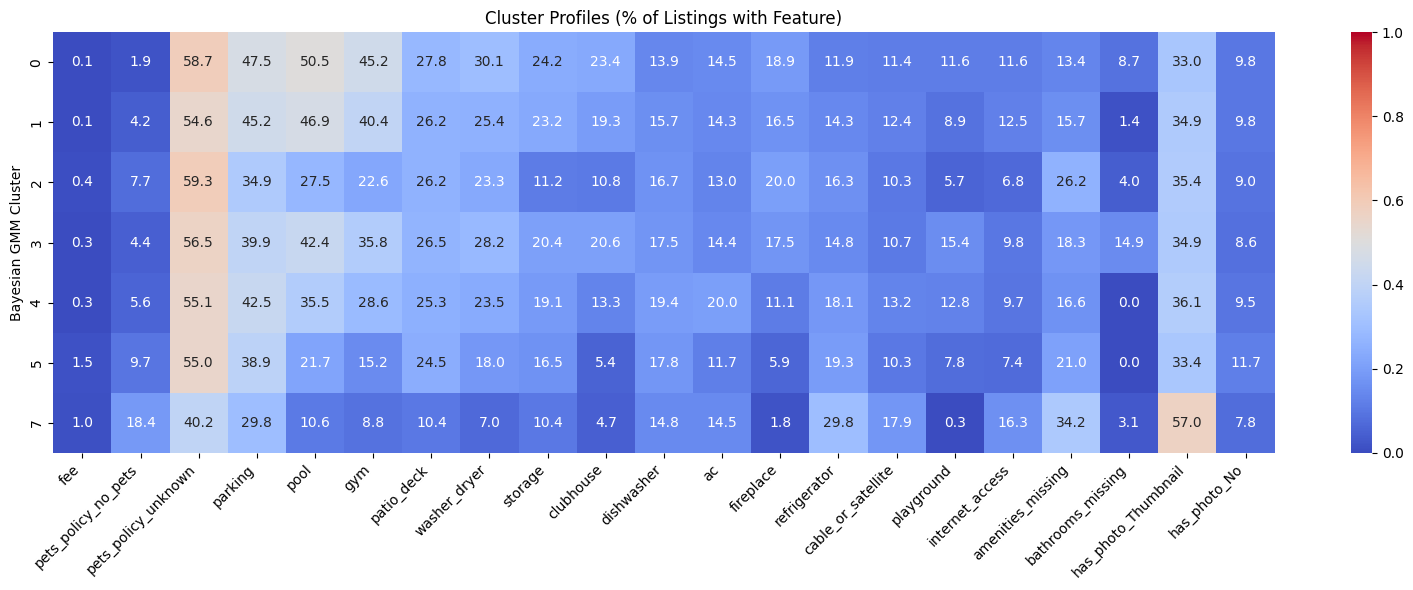

In [234]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    cluster_binary_profile,
    cmap="coolwarm",
    center=0.5,
    vmin=0,
    vmax=1,
    annot=(cluster_binary_profile * 100).round(1),
    fmt=".1f"
)

plt.title("Cluster Profiles (% of Listings with Feature)")
plt.ylabel("Bayesian GMM Cluster")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

The heatmap presents the proportion of listings with each binary feature within each cluster.

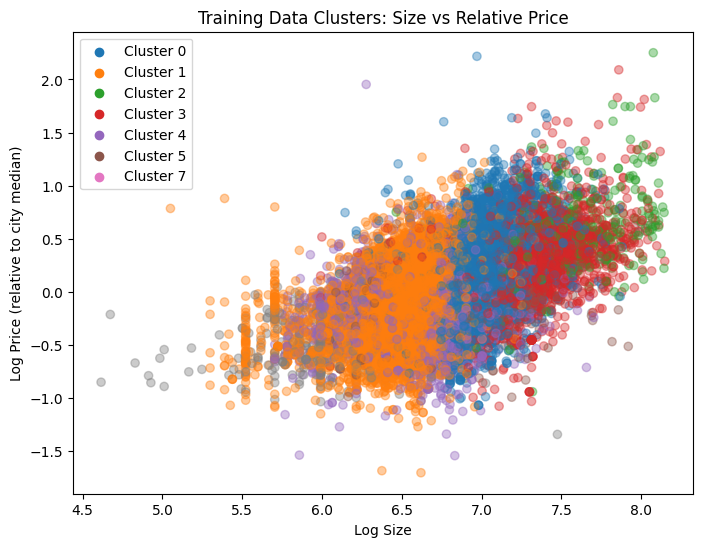

In [235]:
train_plot = train_df

plt.figure(figsize=(8,6))

colors = plt.cm.tab10(train_plot["bayes_cluster"])

plt.scatter(
    train_plot["log_size"],
    train_plot["log_price_centered"],
    c=colors,
    alpha=0.4
)

# legend
for i in sorted(train_plot["bayes_cluster"].unique()):
    plt.scatter([], [], label=f"Cluster {i}")

plt.legend()

plt.xlabel("Log Size")
plt.ylabel("Log Price (relative to city median)")
plt.title("Training Data Clusters: Size vs Relative Price")

plt.show()

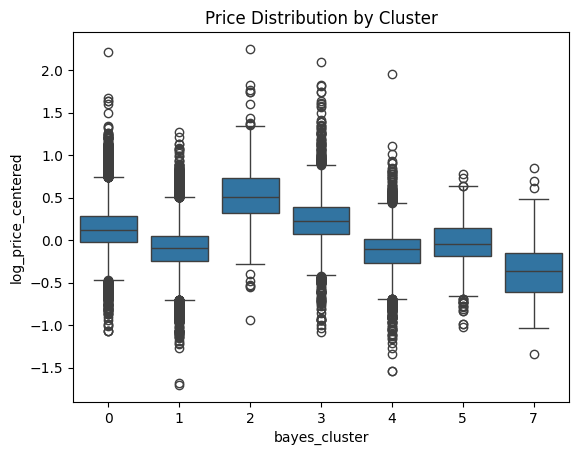

In [236]:
sns.boxplot(x="bayes_cluster", y="log_price_centered", data=train_df)

plt.title("Price Distribution by Cluster")
plt.show()

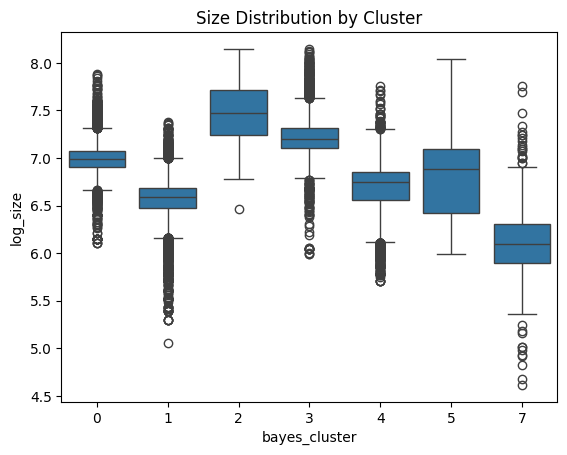

In [237]:
sns.boxplot(x="bayes_cluster", y="log_size", data=train_df)
plt.title("Size Distribution by Cluster")
plt.show()

While the cluster summaries reveal substantial differences in average characteristics and price levels across segments, they do not provide information on how property attributes influence prices within each cluster. To address this, regression models are estimated separately for each cluster.

## Bayesian Linear Regression for each Cluster

 Soft allocation sizes were used to assess cluster uncertainty, but cluster-specific regressions were based on hard cluster allocations.


In [238]:
# Fair cluster comparison:
# pooled Bayesian linear regression model evaluated separately within each Bayesian cluster

cluster_blr_results = {}
cluster_blr_metrics = {}
cluster_dropped_cols = {}

np.random.seed(451)

for cl in sorted(active_clusters):

    train_idx_cl = train_df[train_df["bayes_cluster"] == cl].index
    test_idx_cl = test_df[test_df["bayes_cluster"] == cl].index

    X_train_cl = X_train.loc[train_idx_cl].copy()
    y_train_cl = y_train.loc[train_idx_cl].copy()

    X_test_cl = X_test.loc[test_idx_cl].copy()
    y_test_cl = y_test.loc[test_idx_cl].copy()

    if len(X_train_cl) < 100 or len(X_test_cl) == 0:
        print(f"Skipping cluster {cl}: too few observations")
        continue

    non_constant_cols = X_train_cl.columns[X_train_cl.nunique() > 1]
    dropped_cols = X_train_cl.columns[X_train_cl.nunique() <= 1]

    cluster_dropped_cols[cl] = list(dropped_cols)

    X_train_cl = X_train_cl[non_constant_cols]
    X_test_cl = X_test_cl[non_constant_cols]

    Xtr_cl_bayes = np.column_stack([
        np.ones(X_train_cl.shape[0]),
        X_train_cl.to_numpy()
    ])

    Xte_cl_bayes = np.column_stack([
        np.ones(X_test_cl.shape[0]),
        X_test_cl.to_numpy()
    ])

    ind_names_cl = ["x0"] + list(X_train_cl.columns)

    n_cl, p_cl = Xtr_cl_bayes.shape

    mu_0_cl = np.zeros(p_cl)

    XtX_cl = Xtr_cl_bayes.T @ Xtr_cl_bayes
    Om_0_inv_cl = XtX_cl / n_cl + 1e-6 * np.eye(p_cl)

    try:
        results_cl, mu_n_cl, Om_n_cl, a_n_cl, b_n_cl = BLR(
            Xtr_cl_bayes,
            y_train_cl.to_numpy(),
            mu_0_cl,
            Om_0_inv_cl,
            a_0=0.01,
            b_0=0.01,
            ind_names=ind_names_cl,
            N=10000
        )

        results_cl["cluster"] = cl
        cluster_blr_results[cl] = results_cl

        y_pred_cl = Xte_cl_bayes @ mu_n_cl

        mse_cl = mean_squared_error(y_test_cl, y_pred_cl)

        cluster_blr_metrics[cl] = {
            "n_train": len(X_train_cl),
            "n_test": len(X_test_cl),
            "MSE": mse_cl,
            "RMSE": np.sqrt(mse_cl),
            "R2": r2_score(y_test_cl, y_pred_cl)
        }

    except np.linalg.LinAlgError:
        print(f"Skipping cluster {cl}: singular matrix")

In [239]:
pooled_bayes_preds = pd.Series(
    y_pred_bayes,
    index=X_test.index
)

pooled_cluster_mse = (
    test_df
    .groupby("bayes_cluster")
    .apply(lambda g: mean_squared_error(
        y_test.loc[g.index],
        pooled_bayes_preds.loc[g.index]
    ))
    .rename("pooled_Bayes_MSE")
)

pooled_cluster_rmse = np.sqrt(pooled_cluster_mse).rename("pooled_Bayes_RMSE")

pooled_cluster_mse

bayes_cluster
0    0.055983
1    0.053634
2    0.114634
3    0.073768
4    0.061575
5    0.069908
7    0.072792
Name: pooled_Bayes_MSE, dtype: float64

In [240]:
cluster_metrics_df = (
    pd.DataFrame(cluster_blr_metrics)
    .T
    .reset_index()
    .rename(columns={"index": "cluster"})
)

cluster_metrics_df = cluster_metrics_df.merge(
    pooled_cluster_mse,
    left_on="cluster",
    right_index=True,
    how="left"
)

cluster_metrics_df = cluster_metrics_df.merge(
    pooled_cluster_rmse,
    left_on="cluster",
    right_index=True,
    how="left"
)

cluster_metrics_df["MSE_difference"] = (
    cluster_metrics_df["MSE"] - cluster_metrics_df["pooled_Bayes_MSE"]
)

cluster_metrics_df["RMSE_difference"] = (
    cluster_metrics_df["RMSE"] - cluster_metrics_df["pooled_Bayes_RMSE"]
)

cluster_metrics_df = cluster_metrics_df.round({
    "MSE": 4,
    "RMSE": 4,
    "R2": 4,
    "pooled_Bayes_MSE": 4,
    "pooled_Bayes_RMSE": 4,
    "MSE_difference": 4,
    "RMSE_difference": 4
})

cluster_metrics_df

,cluster,n_train,n_test,MSE,RMSE,R2,pooled_Bayes_MSE,pooled_Bayes_RMSE,MSE_difference,RMSE_difference
0,0,17251.0,4273.0,0.0537,0.2318,0.2393,0.0560,0.2366,-0.0023,-0.0048
1,1,22239.0,5587.0,0.0533,0.2309,0.2093,0.0536,0.2316,-0.0003,-0.0007
2,2,455.0,120.0,0.1123,0.3351,0.1253,0.1146,0.3386,-0.0024,-0.0035
3,3,4659.0,1186.0,0.0722,0.2687,0.1641,0.0738,0.2716,-0.0016,-0.0029
4,4,7086.0,1759.0,0.0563,0.2373,0.0840,0.0616,0.2481,-0.0053,-0.0109
5,5,877.0,230.0,0.0578,0.2405,0.1265,0.0699,0.2644,-0.0121,-0.0239
6,7,386.0,84.0,0.0579,0.2406,0.3011,0.0728,0.2698,-0.0149,-0.0292


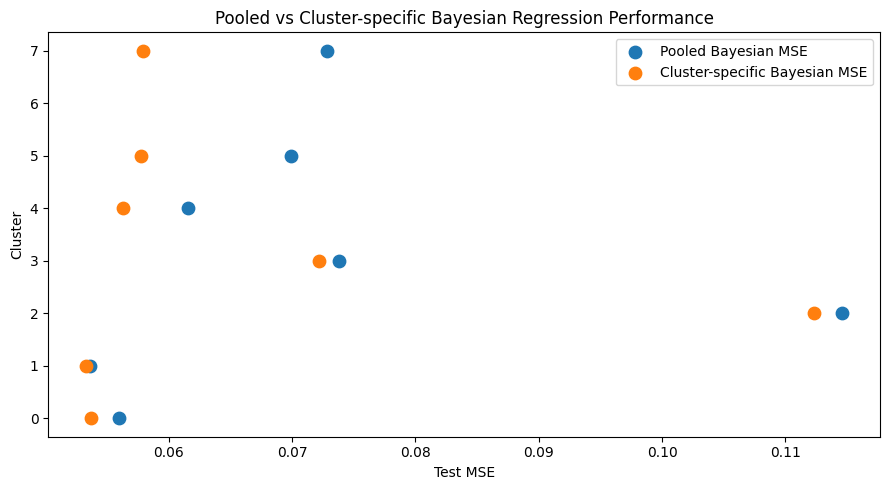

In [241]:
plt.figure(figsize=(9,5))

plt.scatter(
    cluster_metrics_df["pooled_Bayes_MSE"],
    cluster_metrics_df["cluster"],
    s=80,
    label="Pooled Bayesian MSE"
)

plt.scatter(
    cluster_metrics_df["MSE"],
    cluster_metrics_df["cluster"],
    s=80,
    label="Cluster-specific Bayesian MSE"
)

plt.xlabel("Test MSE")
plt.ylabel("Cluster")
plt.title("Pooled vs Cluster-specific Bayesian Regression Performance")

plt.legend()
plt.tight_layout()
plt.show()

This figure compares the predictive performance of cluster-specific Bayesian linear regressions and the corresponding pooled Bayesian linear regression. The pooled model was evaluated separately within each cluster to provide a fair comparison.

The results show that cluster-specific regression improves predictive performance in several clusters, exhibited by lower test MSE values relative to the pooled model. The largest improvements are observed in clusters 4, 5 and 7, suggesting that these segments exhibit heterogeneous relationships between property characteristics and rental prices that are not fully captured by a single global model.

However, the performance of cluster-specific regressions and the pooled regression for clusters 1 and 2 are nearly identical. This suggests that some submarkets are sufficiently homogeneous for the pooled model to perform comparably well.

Overall, the results indicate that clustering can improve prediction accuracy by reducing heterogeneity within rental submarkets.

Since the clusters were defined using structural variables, namely size, bedrooms and bathroom categories, the cluster-specific effect plots focus on non-clustering variables. This allows the analysis to examine which additional listing characteristics explain price differences within each structurally defined segment.

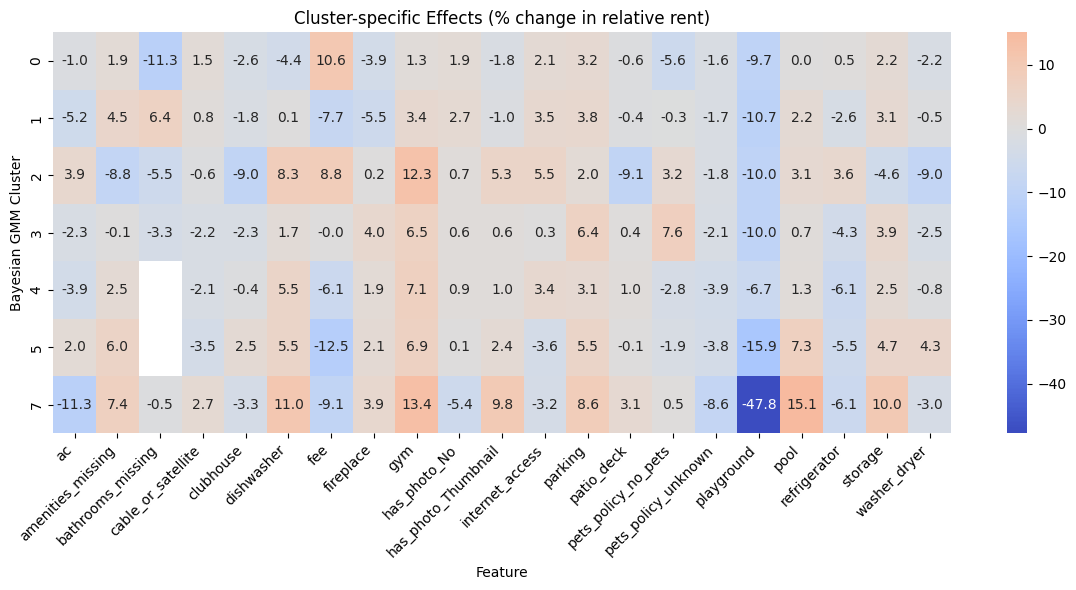

In [242]:
cluster_blr_df = pd.concat(cluster_blr_results.values())

cluster_blr_pct = cluster_blr_df.copy()

cluster_blr_pct["percent_effect"] = (
    np.exp(cluster_blr_pct["posterior mean"]) - 1
) * 100

cluster_blr_pct["lower 95% percent"] = (
    np.exp(cluster_blr_pct["lower 95% bound"]) - 1
) * 100

cluster_blr_pct["upper 95% percent"] = (
    np.exp(cluster_blr_pct["upper 95% bound"]) - 1
) * 100

cluster_defining_features = [
    "log_size",
    "bedrooms",
    "bathrooms_2.0",
    "bathrooms_3.0"
]

cluster_effects_long = (
    cluster_blr_pct
    .reset_index()
    .rename(columns={"index": "feature"})
)

cluster_effects_long = cluster_effects_long[
    ~cluster_effects_long["feature"].isin(
        ["x0"] + cluster_defining_features
    )
]

cluster_effects_table = (
    cluster_effects_long
    .pivot(
        index="cluster",
        columns="feature",
        values="percent_effect"
    )
    .sort_index()
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_effects_table,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".1f"
)

plt.title("Cluster-specific Effects (% change in relative rent)")
plt.xlabel("Feature")
plt.ylabel("Bayesian GMM Cluster")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

This heatmap summarises the cluster-specific Bayesian regression results. Each row represents a Bayesian GMM cluster and each column represents a predictor. The cell values show the estimated percentage effect of each feature on rent within that cluster, based on the posterior mean coefficients. Positive values indicate that the feature is associated with higher rent and negative values indicate lower rent.